# AI Workforce Intelligence, Phase 2: forecasting models and rolling backtests (CS3216 Time Series Analysis and Forecasting)

Phase 2 fits smoothing, ARIMA, machine-learning and ensemble models to each series and compares them all with the same rolling-origin backtest, then picks one model per series.

> **Where this fits.** This is **Phase 2** of 6.
> **Needs:** `outputs/phase1/handoff.json` from Phase 1 (inside the zip).
> **Produces:** `outputs/phase2/chosen_models.json` and the backtest errors `cv_residuals.parquet`, used by Phase 3.

> **How to use this notebook**
> 1. In Colab: *Runtime > Run all*. When asked, upload `ai-workforce-intel_colab.zip` (the same zip for all three notebooks).
> 2. `MODE = "show"` (default) only displays the finished results inside the zip: under 1 minute.
> 3. `MODE = "run"` recomputes **this phase only** (about 4 minutes with --fast, 20 minutes or more for the full run on Colab), using the earlier phases' results in the zip.
> 4. Outside Colab, put the unzipped `ai-workforce-intel` folder (or the zip) next to this notebook.

In [1]:
# ---- Settings: change these, then Runtime > Run all ----
MODE = "show"       # "show": display the finished results in the bundle (under 1 minute)
                    # "run":  recompute Phase 2 first, then display the new results
RUN_FAST = True     # only for MODE = "run": True = --fast, False = full run
WITH_LSTM = False   # only for MODE = "run": also train the optional LSTM challenger (needs torch)
DRIVERS = None      # None = all drivers, or a list such as ["burst_tokens_total_daily"]
PHASE = 2

import os
MODE = os.environ.get("TSAF_MODE", MODE)  # used only by the automated test; ignore in Colab
print("Phase", PHASE, "| MODE =", MODE, "| RUN_FAST =", RUN_FAST, "| DRIVERS =", DRIVERS or "all")

Phase 2 | MODE = show | RUN_FAST = True | DRIVERS = all


### Helper functions
Small helpers used by every step: `step` turns any problem into a one-line message (so *Run all*
never stops), `show_img` and `show_table` display figures and tables at a readable size, and
`show_source` prints a real function from the project.

In [2]:
import contextlib, importlib, inspect, json, re, subprocess, sys, time, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

@contextlib.contextmanager
def step(name):
    """Run one notebook step; a problem prints a short message instead of a traceback."""
    try:
        yield
    except FileNotFoundError as exc:
        print(f"[{name}] skipped: a result file is missing ({Path(str(exc.filename or exc)).name}).")
    except Exception as exc:
        print(f"[{name}] skipped: {type(exc).__name__}: {str(exc)[:200]}")

def show_img(path, width=900):
    """Display a saved PNG figure, or a short message if it does not exist."""
    path = Path(path)
    if not path.exists():
        print(f"No figure {path.name}; skipped.")
        return
    display(Image(filename=str(path), width=width))

def show_table(df, n=10, cols=None, digits=3):
    """Display the first n rows of a table, selected columns, rounded numbers."""
    if df is None or len(df) == 0:
        print("No rows to show.")
        return
    df = df[[c for c in cols if c in df.columns]] if cols else df
    display(df.head(n).round(digits).reset_index(drop=True))

def read_table(phase, name):
    """Read outputs/<phase>/tables/<name>.csv."""
    return pd.read_csv(Path("outputs") / phase / "tables" / f"{name}.csv")

def md_section(path, title):
    """Text of the '## ... title ...' section of a generated summary file (None if absent)."""
    text = Path(path).read_text(encoding="utf-8")
    pat = r"^## [^\n]*" + re.escape(title) + r"[^\n]*\n(.*?)(?=^## |\Z)"
    m = re.search(pat, text, flags=re.M | re.S)
    return m.group(1).strip() if m else None

def show_source(module, func, max_lines=25):
    """Print the source of module.func (first max_lines lines), or a short message."""
    try:
        obj = getattr(importlib.import_module(module), func)
        lines = inspect.getsource(obj).splitlines()
    except Exception as exc:
        print(f"Could not find {module}.{func}: {type(exc).__name__}; skipped.")
        return
    more = f"\n# ... {len(lines) - max_lines} more lines" if len(lines) > max_lines else ""
    display(Markdown(f"`{module}.{func}`\n```python\n" + "\n".join(lines[:max_lines]) + more + "\n```"))

## Setup 1: get the project
If the project folder is not here yet, the cell asks you to upload `ai-workforce-intel_colab.zip`
(about 10 MB), unzips it and moves into the folder. Outside Colab it looks for the folder (or the zip)
next to the notebook. The commented lines show how to unzip it from Google Drive instead.

In [3]:
def _is_project(p):
    return (p / "src" / "run_phase2.py").exists()

def _find_project():
    here = Path.cwd()
    for c in (here, here / "ai-workforce-intel", Path("/content/ai-workforce-intel")):
        if _is_project(c):
            return c
    return None

def _get_zip():
    if os.environ.get("TSAF_BUNDLE_PATH"):          # automated test: no upload dialog
        return Path(os.environ["TSAF_BUNDLE_PATH"])
    if Path("ai-workforce-intel_colab.zip").exists():
        return Path("ai-workforce-intel_colab.zip")
    try:
        from google.colab import files               # only exists inside Colab
    except ImportError:
        print("Not in Colab: place ai-workforce-intel_colab.zip or the unzipped folder next to this notebook.")
        return None
    print("Please upload ai-workforce-intel_colab.zip")
    uploaded = files.upload()
    return Path(next(iter(uploaded))) if uploaded else None

# Alternative: unzip from Google Drive instead of uploading (uncomment the two lines):
# from google.colab import drive; drive.mount("/content/drive")
# import zipfile; zipfile.ZipFile("/content/drive/MyDrive/ai-workforce-intel_colab.zip").extractall("/content")

PROJECT = None
with step("get the project"):
    PROJECT = _find_project()
    if PROJECT is None:
        zpath = _get_zip()
        if zpath is not None and zpath.exists():
            import zipfile
            base = Path("/content") if Path("/content").is_dir() else Path.cwd()
            zipfile.ZipFile(zpath).extractall(base)
            PROJECT = base / "ai-workforce-intel"
    if PROJECT is not None and _is_project(PROJECT):
        os.chdir(PROJECT)
        if str(PROJECT / "src") not in sys.path:
            sys.path.insert(0, str(PROJECT / "src"))
        print("Project ready: working folder is", Path.cwd().name)
    else:
        print("Project not found. Upload the zip and run this cell again.")

Project ready: working folder is ai-workforce-intel


## Setup 2: packages
Colab already has pandas, numpy, statsmodels, scikit-learn, matplotlib and pyarrow. This cell installs
only what is missing from `requirements.txt`, plus `xgboost` if it is missing. Prophet and torch are
optional and are never installed automatically.

In [4]:
IMPORT_NAME = {"scikit-learn": "sklearn"}
with step("packages"):
    wanted = []
    for line in Path("requirements.txt").read_text().splitlines():
        line = line.split("#")[0].strip()
        if line:
            wanted.append(re.split(r"[<>=!~ ]", line)[0])
    missing = []
    for pkg in wanted + ["xgboost"]:
        try:
            importlib.import_module(IMPORT_NAME.get(pkg, pkg))
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=False)
    else:
        print("All required packages are already installed.")
    import numpy, statsmodels, sklearn, matplotlib
    print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {numpy.__version__} | "
          f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
    import optional
    for name, ok in [("xgboost", optional.has_xgboost()), ("prophet", optional.has_prophet()), ("torch (LSTM)", optional.has_torch())]:
        print(f"  optional {name:13s}: {'available' if ok else 'not installed (model skipped)'}")

All required packages are already installed.
Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | statsmodels 0.15.0 | scikit-learn 1.9.0 | matplotlib 3.11.1


  optional xgboost      : available
  optional prophet      : not installed (model skipped)
  optional torch (LSTM) : available


## Setup 3: seeds and project layout
All randomness uses seed 42, so a rerun gives the same numbers.

In [5]:
with step("seeds and tree"):
    import random, numpy as np
    random.seed(42)
    np.random.seed(42)
    for top in sorted(p for p in Path(".").iterdir() if p.is_dir() and not p.name.startswith(".")):
        subs = sorted(q.name for q in top.iterdir() if q.is_dir() and q.name != "__pycache__")
        print(f"{top.name}/" + (f"  ->  {', '.join(subs)}" if subs else ""))

data/  ->  processed
outputs/  ->  phase1, phase2, phase3
reports/  ->  figures
src/  ->  tsaf
tests/


## Run (only when `MODE = "run"`)
In `show` mode nothing is recomputed. In `run` mode this cell runs `python src/run_phase2.py` exactly as in a
terminal (this phase only; earlier phases' results come from the zip), then the notebook shows the new results.

In [6]:
def run_script(args):
    """Run one project script and print the last lines of its log."""
    t0 = time.time()
    res = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    for line in (res.stdout + res.stderr).strip().splitlines()[-8:]:
        print("   ", line[:150])
    print(f"  -> exit code {res.returncode}, {time.time() - t0:.0f} s")
    return res.returncode

with step("run"):
    if MODE == "run":
        extra = ["--drivers", *DRIVERS] if DRIVERS else []
        fast = ["--fast"] if RUN_FAST else []
        print("Estimated time on Colab's CPU: about 4 minutes with --fast, 20 minutes or more for the full run.")
        T0 = time.time()
        run_script(["src/run_phase2.py", *fast, *(["--with-lstm"] if WITH_LSTM else []), *extra])
        print(f"Total elapsed: {(time.time() - T0) / 60:.1f} minutes")
    else:
        print("MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).")

MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).


In [7]:
NAMES, HANDOFF = [], {"drivers": []}
with step("drivers"):
    HANDOFF = json.loads(Path("outputs/phase1/handoff.json").read_text(encoding="utf-8"))
    NAMES = [d["name"] for d in HANDOFF["drivers"] if not DRIVERS or d["name"] in DRIVERS]
    print(f"{len(NAMES)} drivers:", ", ".join(NAMES))

7 drivers: burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily, burst_requests_hourly, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly


# Part C: Phase 2, forecasting models

## C1. The model families
- **baseline**: the five Phase 1 benchmarks.
- **smoothing**: moving average and exponential smoothing (SES, Holt, damped Holt, Holt-Winters), which weight recent values more.
- **arima**: ARIMA, seasonal SARIMA, and SARIMAX with extra inputs (weekend dummy, or Fourier sine/cosine terms for hourly data).
- **ml**: Ridge regression, random forest and XGBoost on lag features, forecasting one step at a time.
- **deep**: optional Prophet and LSTM challengers.
- **ensemble**: the average of the two best models.

The table lists every registered model and the series it actually ran on (from the leaderboard).

In [8]:
with step("families"):
    from tsaf.models.registry import build_registry
    lb = read_table("phase2", "leaderboard")
    rows = []
    for model, family in [(s.name, s.family) for s in build_registry()] + [("ensemble", "ensemble")]:
        ok = lb[(lb["model"] == model) & (lb["status"] == "ok")]["driver"].tolist()
        rows.append({"family": family, "model": model,
                     "ran on": f"{len(ok)} series" + (f": {', '.join(ok)}" if 0 < len(ok) < 4 else "")
                     if ok else "not run (reason in leaderboard.csv)"})
    show_table(pd.DataFrame(rows), n=40)

,family,model,ran on
0,baseline,naive,7 series
1,baseline,seasonal_naive,7 series
2,baseline,mean,7 series
3,baseline,drift,7 series
4,baseline,seasonal_ma3,7 series
5,smoothing,moving_average,7 series
6,smoothing,ses,7 series
7,smoothing,holt,7 series
8,smoothing,damped_holt,7 series
9,smoothing,hw_additive,7 series


## C2. How the models are compared
Every model gets **exactly the same test**: an *expanding-window rolling-origin backtest*. The training
window (blue) grows, the test window (orange) moves forward, and the **hold-out** at the end (grey) is
used once, at the very end, never for choosing. The diagram uses the real settings of BurstGPT daily
tokens. A model "wins" a series only if its mean cross-validation (CV) **MASE** is below seasonal naive's.

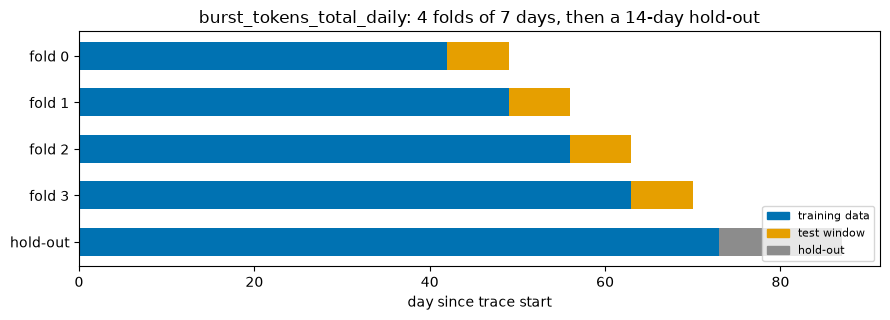

In [9]:
with step("backtest diagram"):
    import matplotlib.pyplot as plt
    from tsaf import backtest
    d = next(x for x in HANDOFF["drivers"] if x["grain"] == "daily")
    cv, n = d["cv_settings"], d["n_obs"]
    origins = backtest.fold_origins(n - cv["holdout"], cv["initial"], cv["h"], cv["step"])
    fig, ax = plt.subplots(figsize=(9, 0.55 * (len(origins) + 2)))
    for i, o in enumerate(origins):
        ax.barh(i, o, color="#0072B2", height=0.6)
        ax.barh(i, cv["h"], left=o, color="#E69F00", height=0.6)
    k = len(origins)
    ax.barh(k, n - cv["holdout"], color="#0072B2", height=0.6)
    ax.barh(k, cv["holdout"], left=n - cv["holdout"], color="#8C8C8C", height=0.6)
    ax.set_yticks(range(k + 1), [f"fold {i}" for i in range(k)] + ["hold-out"])
    ax.invert_yaxis()
    ax.set_xlabel("day since trace start")
    ax.set_title(f"{d['name']}: {k} folds of {cv['h']} days, then a {cv['holdout']}-day hold-out")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#0072B2", "#E69F00", "#8C8C8C")],
              labels=["training data", "test window", "hold-out"], loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

## C3. Leaderboards
For each series: bars of mean CV MASE per model (shorter is better), the dashed line is seasonal naive,
the blue bar is the chosen model. The table shows the top 5 with the **share of folds** in which the
model beat seasonal naive and its **hold-out MASE** (the final, untouched test).

**burst_tokens_total_daily**

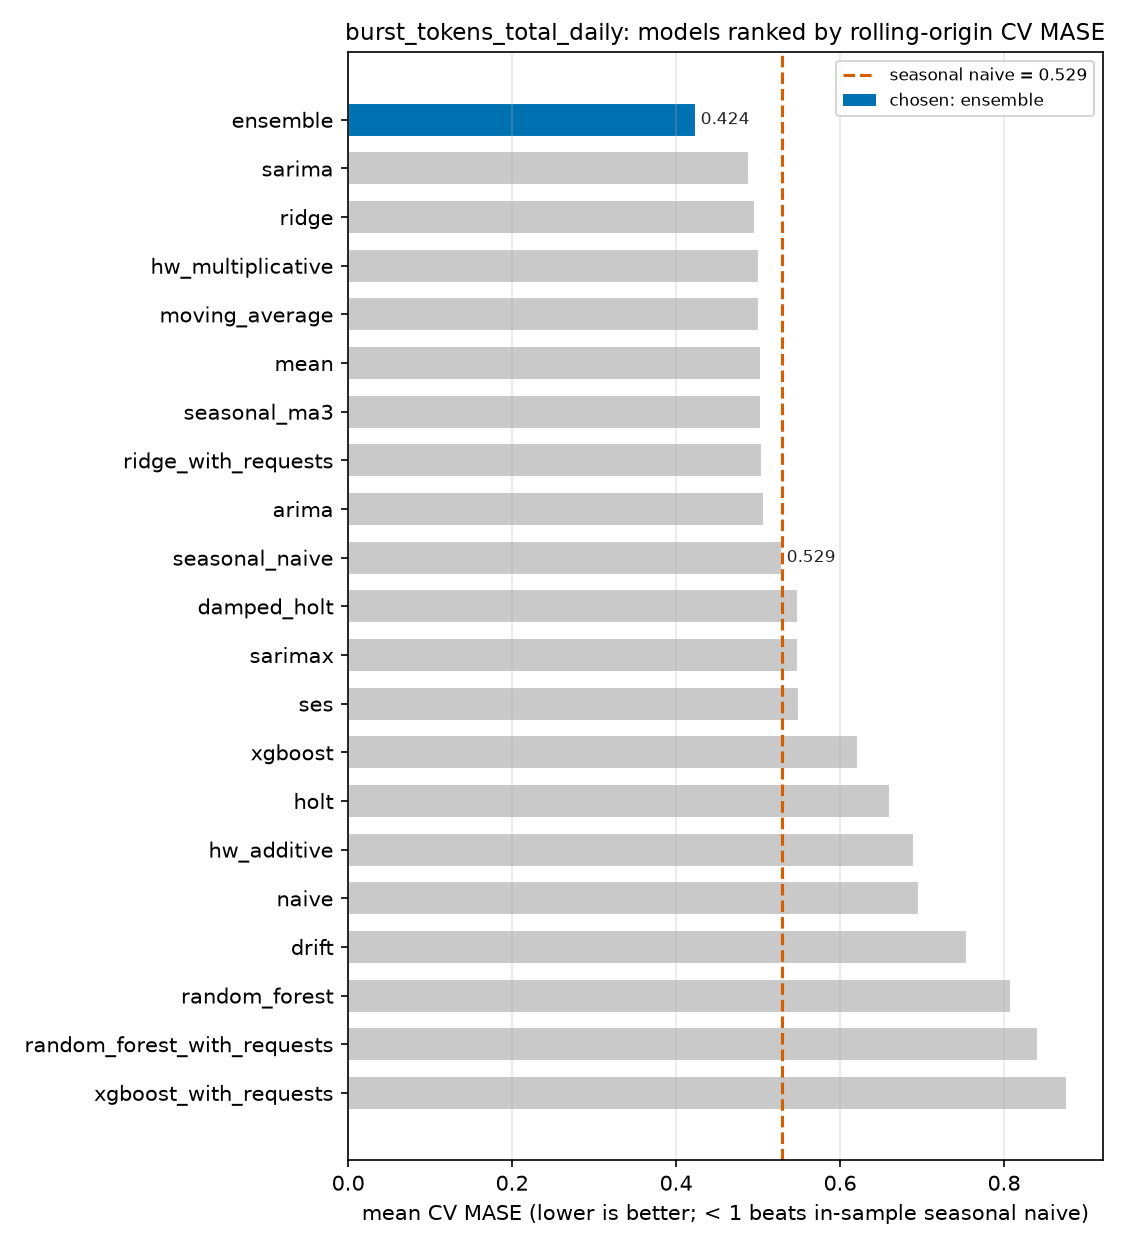

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.424,0.75,1.003
1,sarima,arima,0.489,0.50,0.911
2,ridge,ml,0.496,0.50,1.095
3,hw_multiplicative,smoothing,0.502,0.50,1.057
4,moving_average,smoothing,0.502,0.50,0.775


**burst_tokens_api_daily**

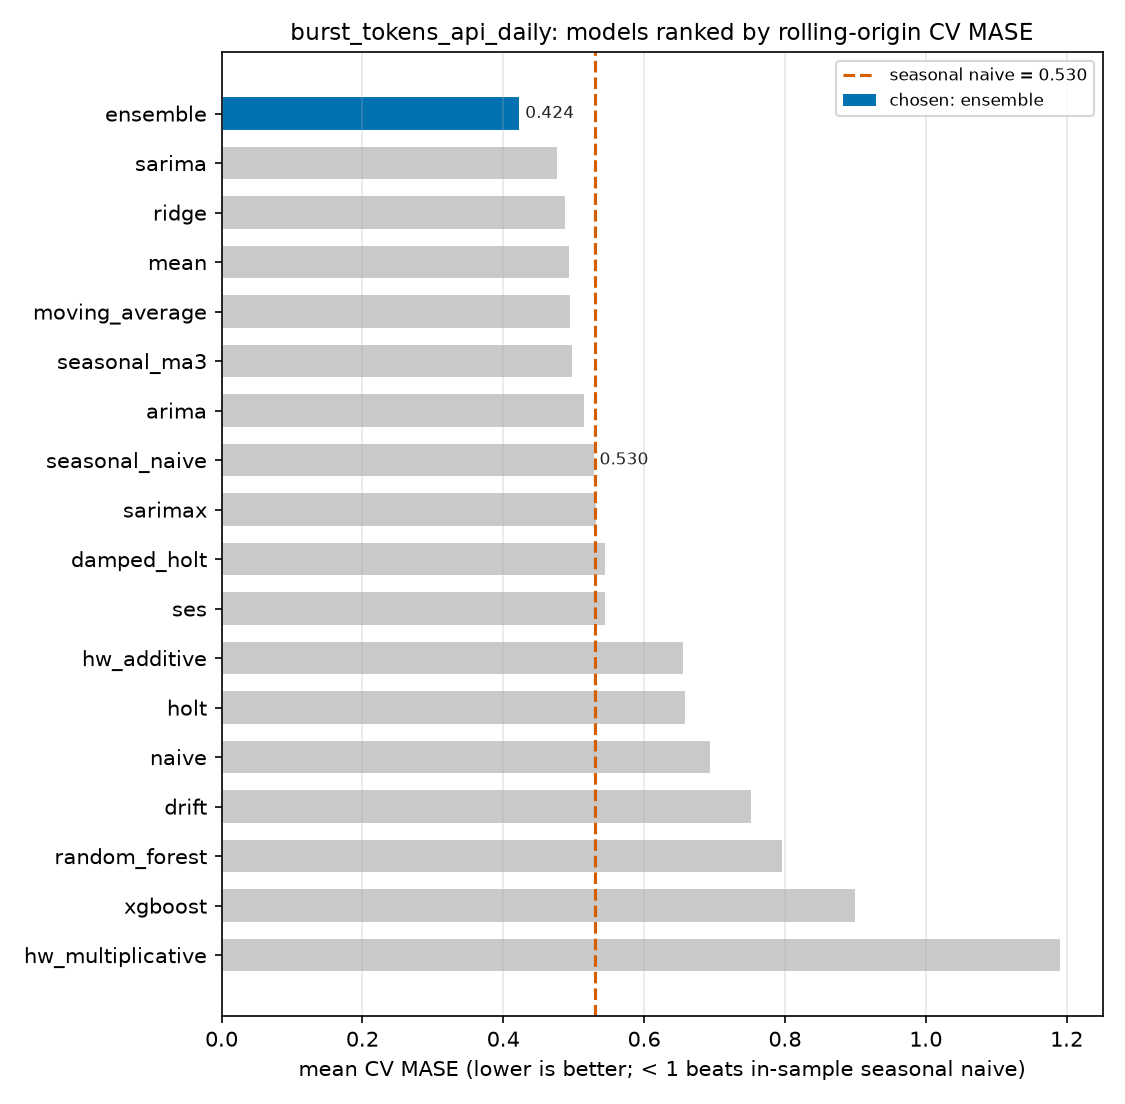

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.424,0.75,1.030
1,sarima,arima,0.478,0.50,0.948
2,ridge,ml,0.489,0.50,1.113
3,mean,baseline,0.495,0.50,0.909
4,moving_average,smoothing,0.496,0.50,0.770


**burst_tokens_chat_daily**

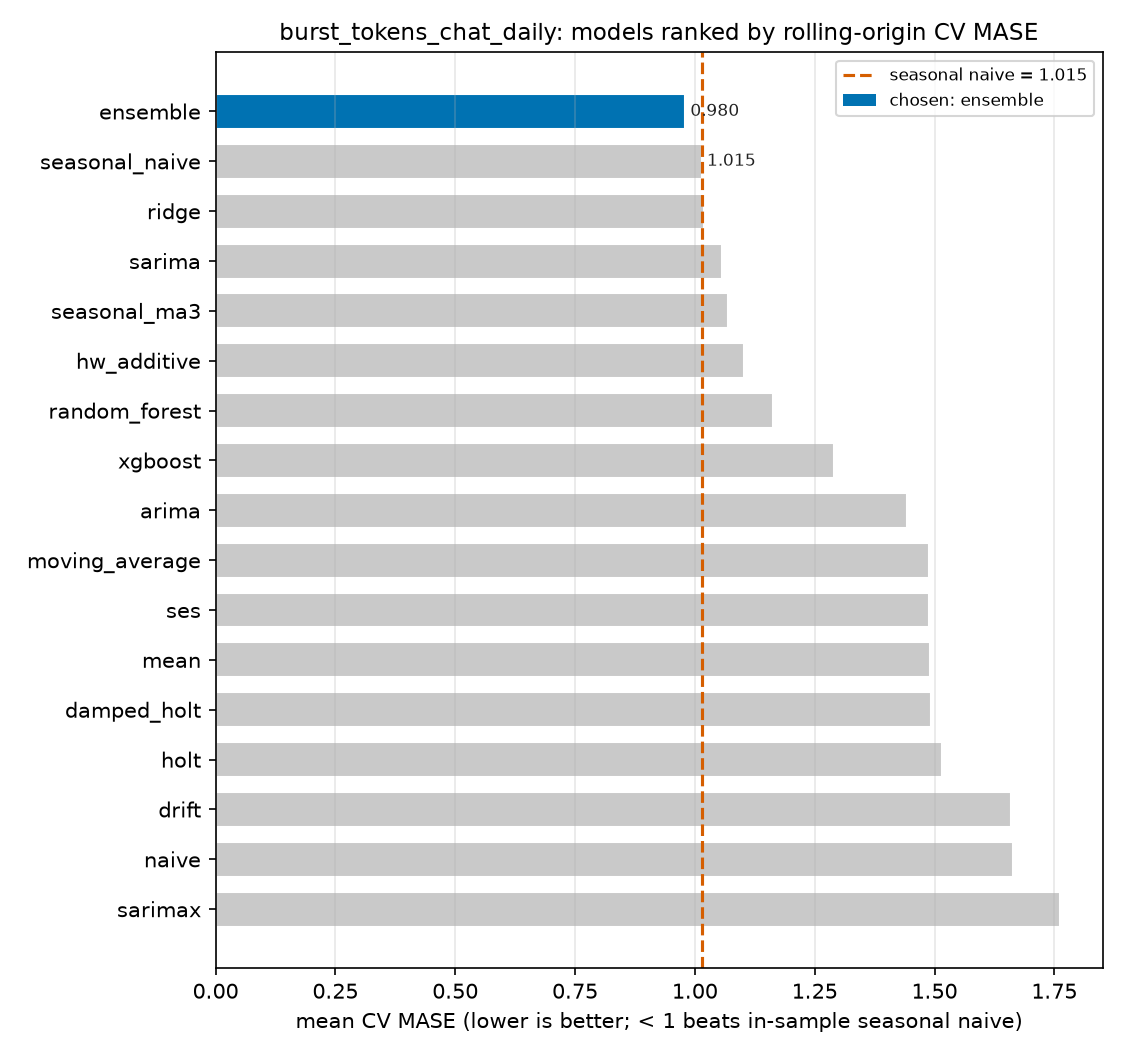

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.980,0.75,2.001
1,seasonal_naive,baseline,1.015,0.00,2.002
2,ridge,ml,1.019,0.75,2.035
3,sarima,arima,1.056,0.50,2.044
4,seasonal_ma3,baseline,1.069,0.75,2.109


**burst_requests_hourly**

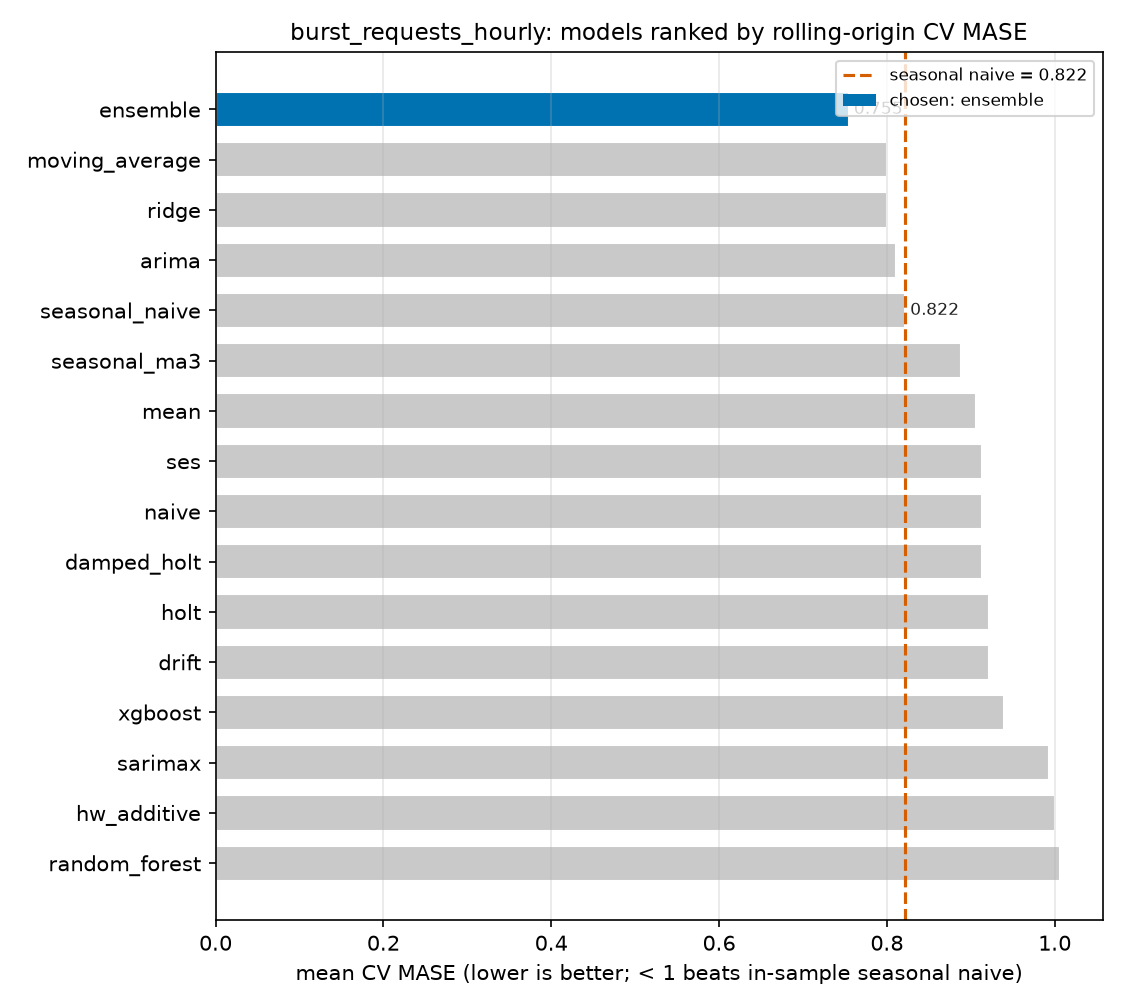

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.755,0.750,1.834
1,moving_average,smoothing,0.800,0.375,1.921
2,ridge,ml,0.800,0.625,1.782
3,arima,arima,0.810,0.375,1.677
4,seasonal_naive,baseline,0.822,0.000,2.413


**wildchat_conversations_daily**

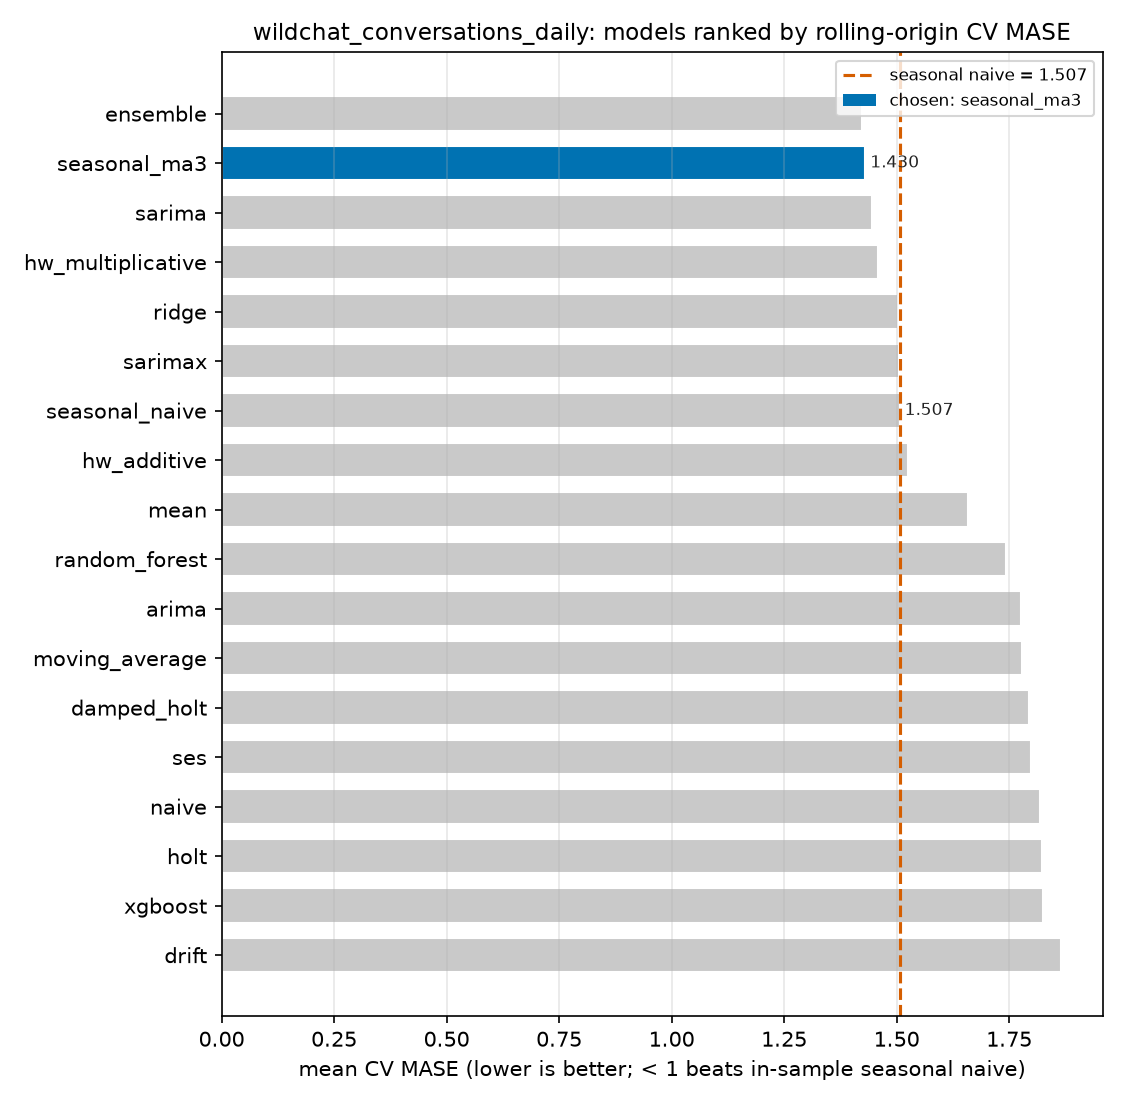

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,1.423,0.333,2.071
1,seasonal_ma3,baseline,1.430,0.222,2.451
2,sarima,arima,1.445,0.444,1.692
3,hw_multiplicative,smoothing,1.459,0.556,1.745
4,ridge,ml,1.503,0.556,1.770


**eci_wages_quarterly**

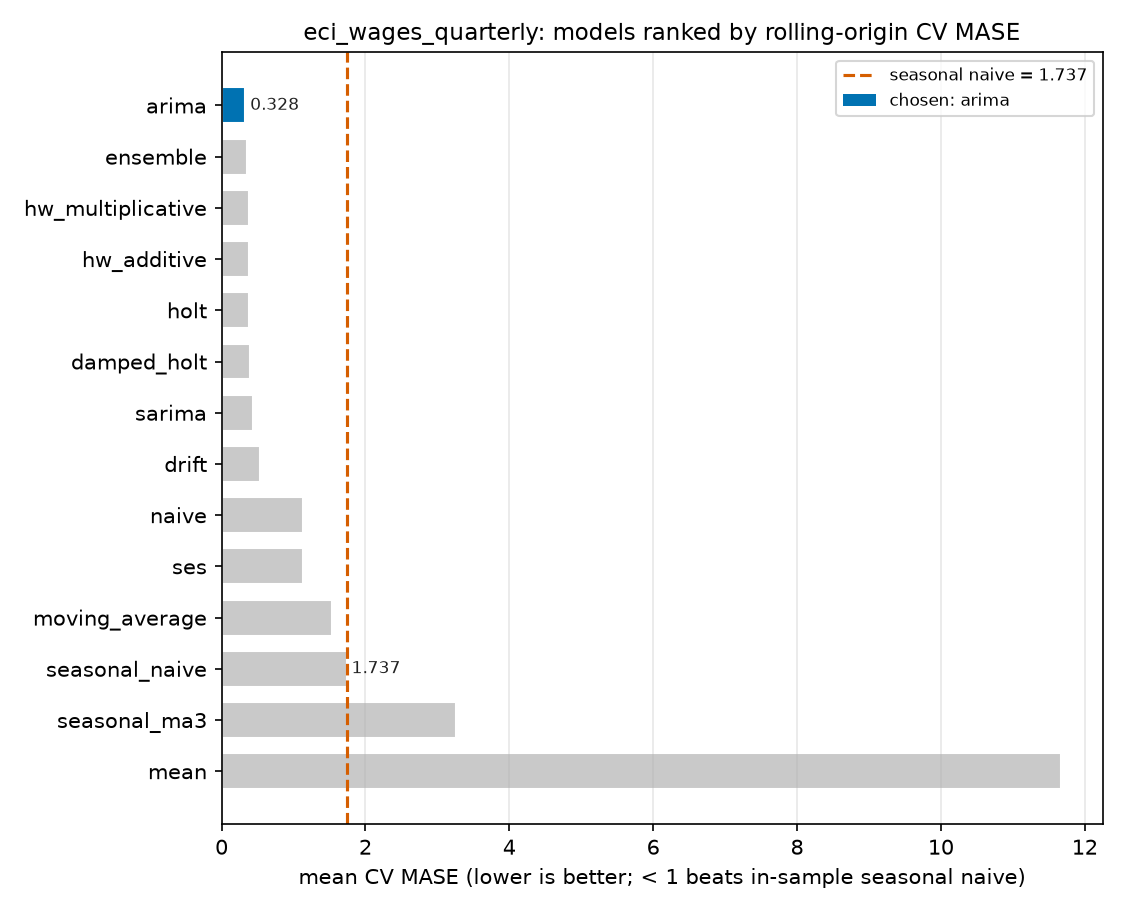

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,arima,arima,0.328,1.0,0.353
1,ensemble,ensemble,0.351,1.0,0.274
2,hw_multiplicative,smoothing,0.376,1.0,0.195
3,hw_additive,smoothing,0.379,1.0,0.190
4,holt,smoothing,0.386,1.0,0.197


**ppi_hosting_monthly**

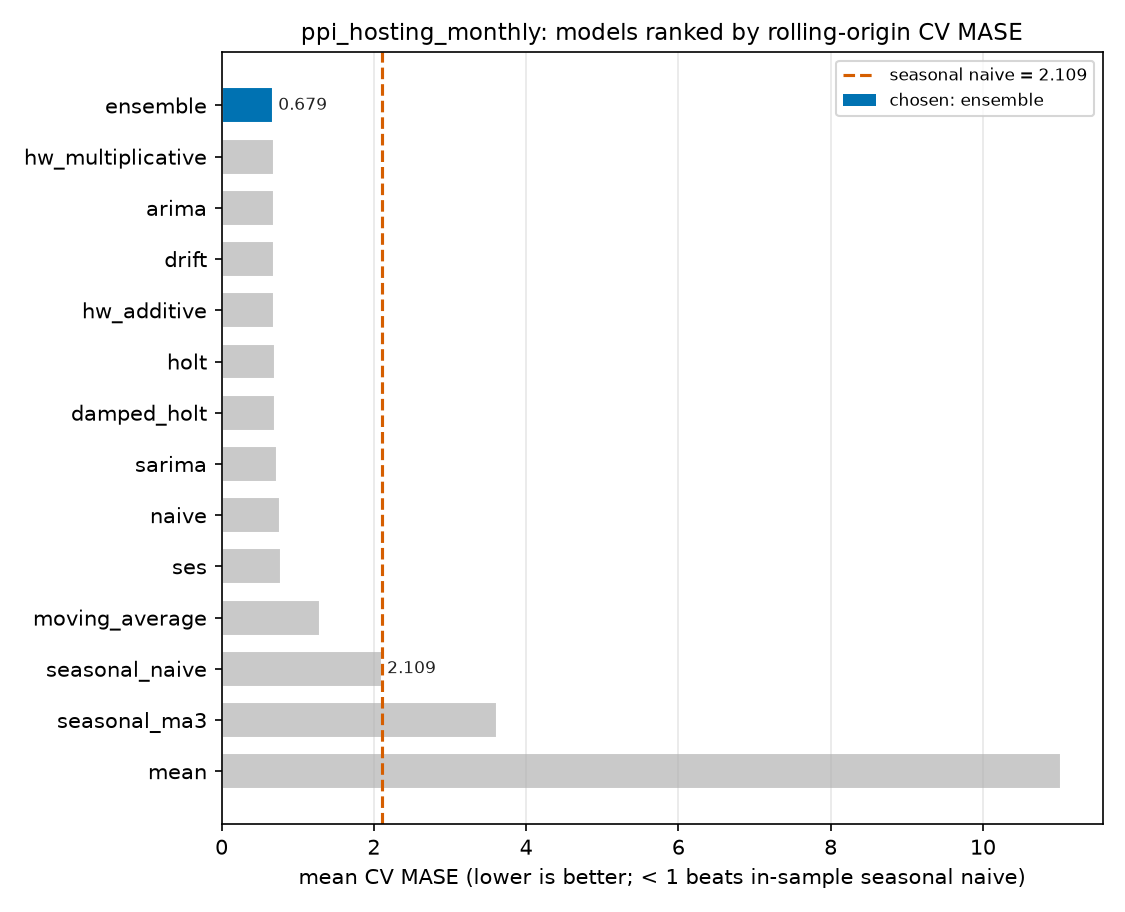

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.679,0.921,2.376
1,hw_multiplicative,smoothing,0.686,0.895,2.444
2,arima,arima,0.689,0.921,2.309
3,drift,baseline,0.690,0.868,2.649
4,hw_additive,smoothing,0.694,0.895,2.462


In [10]:
with step("leaderboards"):
    lb = read_table("phase2", "leaderboard")
    ok = lb[lb["status"] == "ok"]
    for name in NAMES:
        display(Markdown(f"**{name}**"))
        show_img(f"outputs/phase2/figures/leaderboard_{name}.png", width=650)
        top = ok[ok["driver"] == name].sort_values("cv_mase").head(5)
        show_table(top, cols=["model", "family", "cv_mase", "share_beats_snaive", "holdout_mase"])

## C4. The chosen model per series
The rule: rank by mean CV MASE; a model is chosen only if it beats seasonal naive; ties within 1% go to
the simpler family. The `why` column shows the rule that was applied.

In [11]:
with step("chosen models"):
    ch = read_table("phase2", "chosen_models")
    show_table(ch, n=20, cols=["driver", "chosen_model", "family", "cv_mase", "holdout_mase",
                               "seasonal_naive_cv_mase", "beats_seasonal_naive", "why"])
    n_ens = int((ch["family"] == "ensemble").sum())
    n_base = int((ch["family"] == "baseline").sum())
    print(f"Won by the ensemble: {n_ens} | by a single model: {len(ch) - n_ens - n_base} | "
          f"by a baseline: {n_base} (of {len(ch)} series)")

,driver,chosen_model,family,cv_mase,holdout_mase,seasonal_naive_cv_mase,beats_seasonal_naive,why
0,burst_tokens_total_daily,ensemble,ensemble,0.424,1.003,0.529,True,"lowest mean CV MASE 0.424, below seasonal naive 0.529"
1,burst_tokens_api_daily,ensemble,ensemble,0.424,1.030,0.530,True,"lowest mean CV MASE 0.424, below seasonal naive 0.530"
2,burst_tokens_chat_daily,ensemble,ensemble,0.980,2.001,1.015,True,"lowest mean CV MASE 0.980, below seasonal naive 1.015"
3,burst_requests_hourly,ensemble,ensemble,0.755,1.834,0.822,True,"lowest mean CV MASE 0.755, below seasonal naive 0.822"
4,wildchat_conversations_daily,seasonal_ma3,baseline,1.430,2.451,1.507,True,"lowest mean CV MASE 1.430 (within 1% of the best, 1.423; simpler family preferred), be..."
5,eci_wages_quarterly,arima,arima,0.328,0.353,1.737,True,"lowest mean CV MASE 0.328, below seasonal naive 1.737"
6,ppi_hosting_monthly,ensemble,ensemble,0.679,2.376,2.109,True,"lowest mean CV MASE 0.679, below seasonal naive 2.109"


Won by the ensemble: 5 | by a single model: 1 | by a baseline: 1 (of 7 series)


## C5. Ensemble check: is the ensemble really better?
The ensemble averages the two models with the best CV MASE, so it was **chosen on the same CV folds**
it is scored on, and its CV score is optimistic. The **hold-out** was never used for choosing, so it is the
fair check: compare the ensemble's hold-out MASE with seasonal naive's on the same hold-out.

In [12]:
with step("ensemble check"):
    lb = read_table("phase2", "leaderboard").set_index(["driver", "model"])
    ch = read_table("phase2", "chosen_models").set_index("driver")
    rows = []
    for name in NAMES:
        if (name, "ensemble") not in lb.index:
            continue
        e, s = lb.loc[(name, "ensemble")], lb.loc[(name, "seasonal_naive")]
        rows.append({"driver": name, "chosen": ch.loc[name, "chosen_model"] if name in ch.index else "",
                     "ensemble of": e["reason"].replace("average of ", ""),
                     "ensemble CV MASE": e["cv_mase"], "ensemble hold-out MASE": e["holdout_mase"],
                     "seasonal naive hold-out MASE": s["holdout_mase"],
                     "ensemble better on hold-out": bool(e["holdout_mase"] < s["holdout_mase"])})
    show_table(pd.DataFrame(rows), n=20)

,driver,chosen,ensemble of,ensemble CV MASE,ensemble hold-out MASE,seasonal naive hold-out MASE,ensemble better on hold-out
0,burst_tokens_total_daily,ensemble,sarima and ridge,0.424,1.003,1.435,True
1,burst_tokens_api_daily,ensemble,sarima and ridge,0.424,1.030,1.443,True
2,burst_tokens_chat_daily,ensemble,seasonal_naive and ridge,0.980,2.001,2.002,True
3,burst_requests_hourly,ensemble,moving_average and ridge,0.755,1.834,2.413,True
4,wildchat_conversations_daily,seasonal_ma3,seasonal_ma3 and sarima,1.423,2.071,1.542,False
5,eci_wages_quarterly,arima,arima and hw_multiplicative,0.351,0.274,1.326,True
6,ppi_hosting_monthly,ensemble,hw_multiplicative and arima,0.679,2.376,1.742,False


## C6. Forecasts on the hold-out
History in black, the hold-out actual with dots, the chosen model in blue with its **80% and 95%
prediction intervals** (built from the model's own backtest errors), and seasonal naive dashed for comparison.

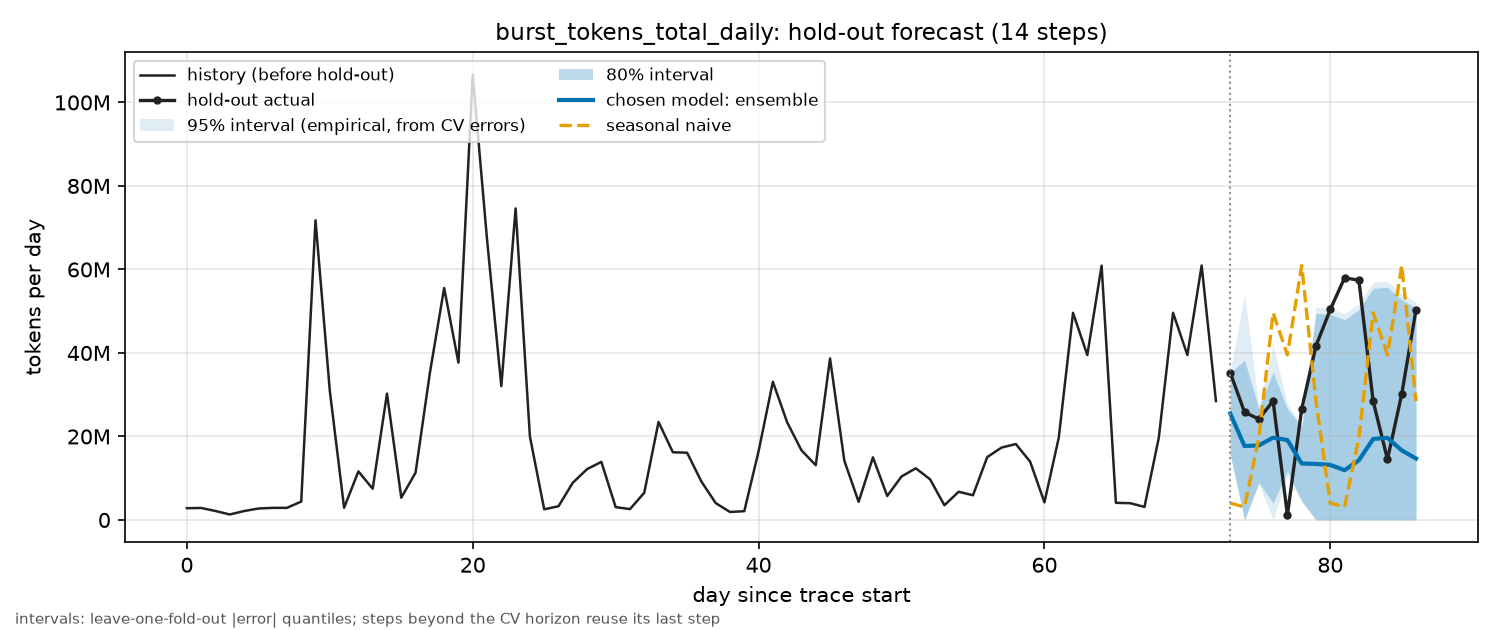

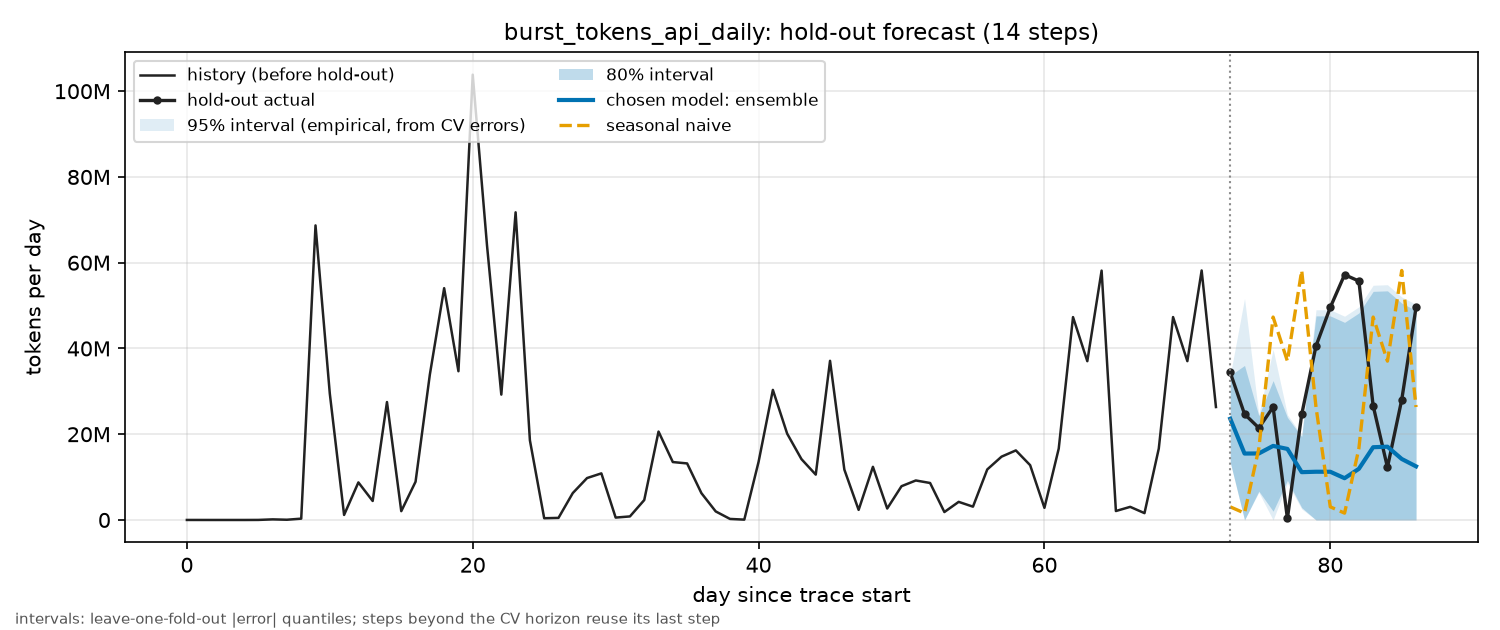

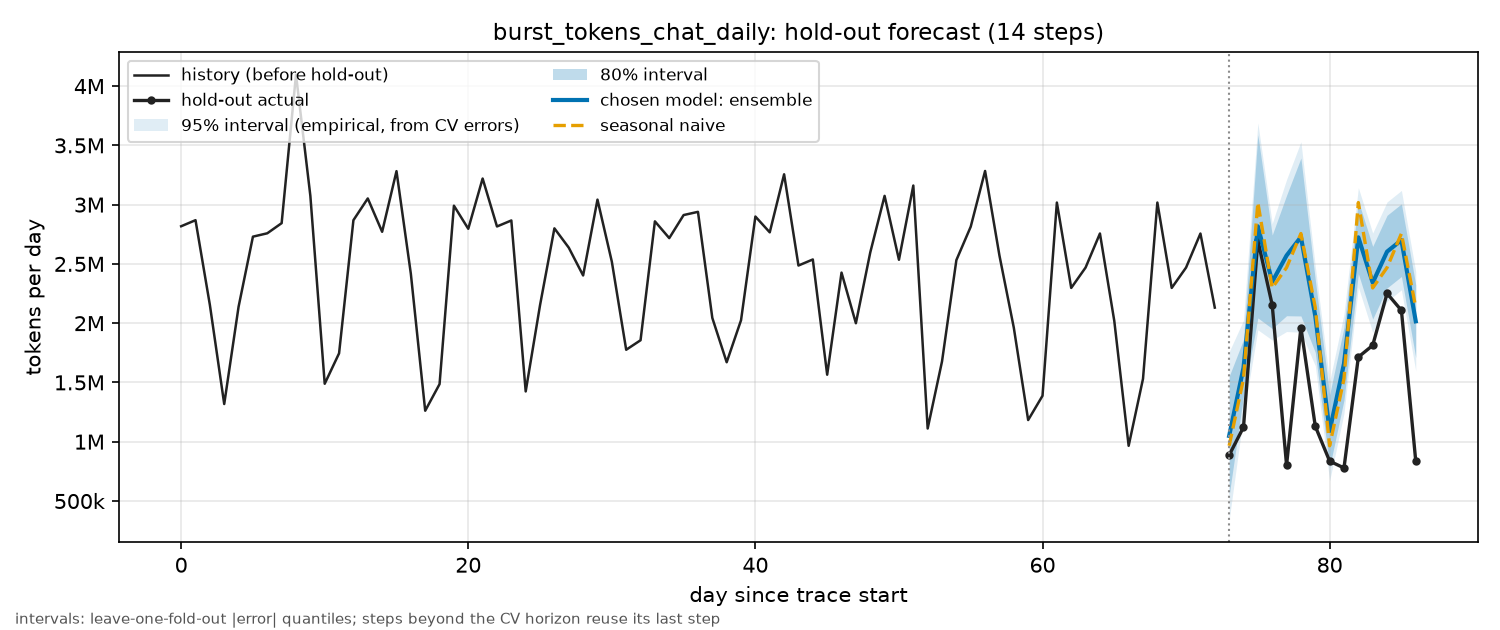

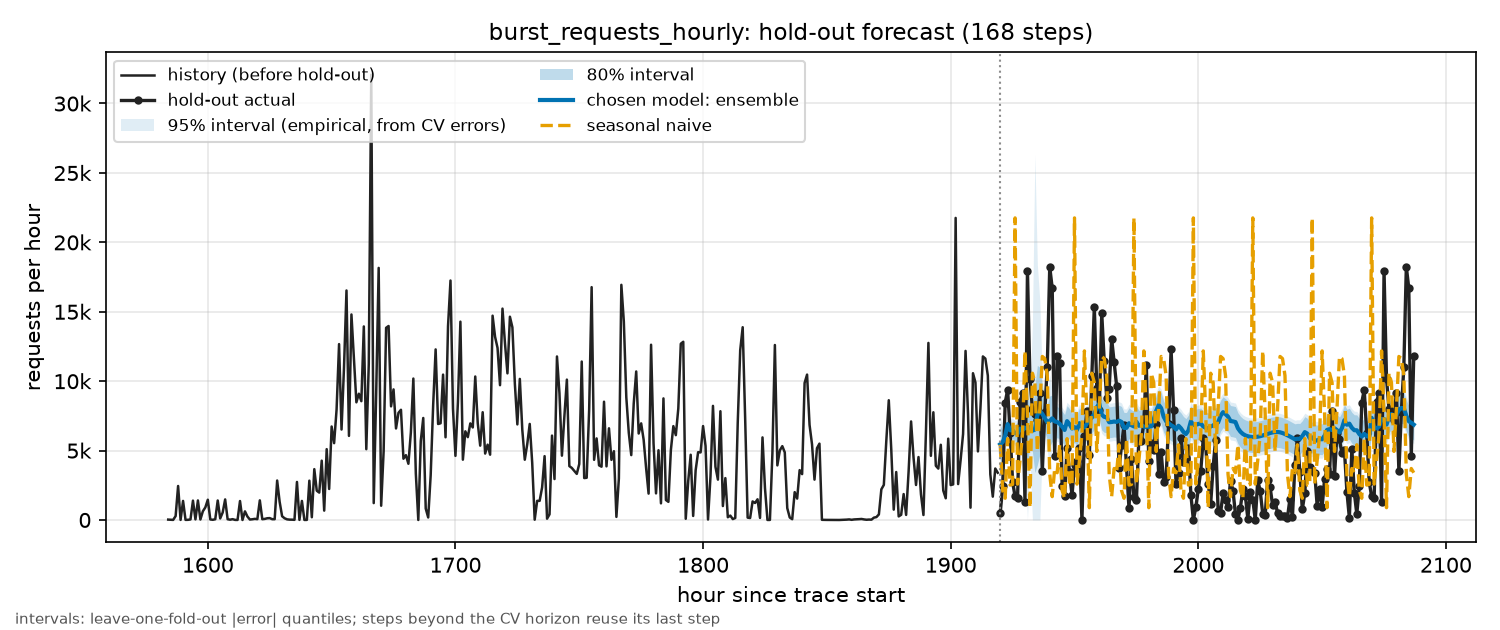

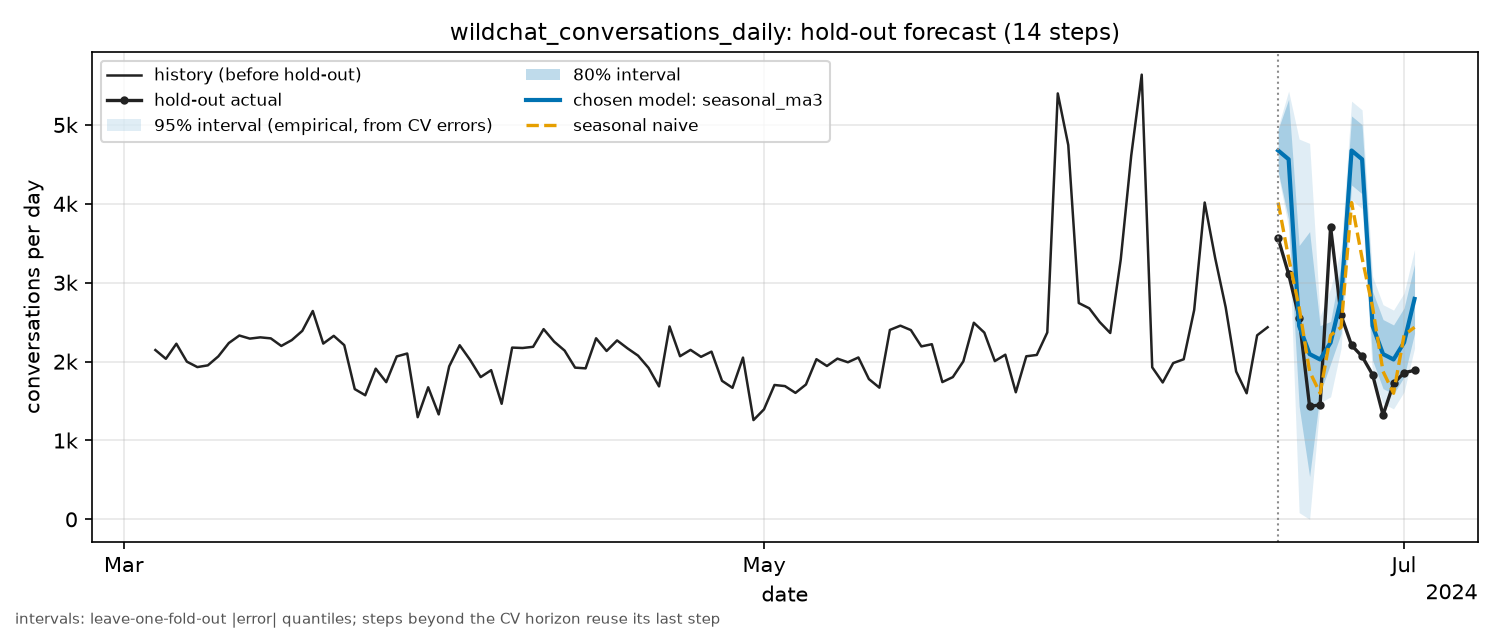

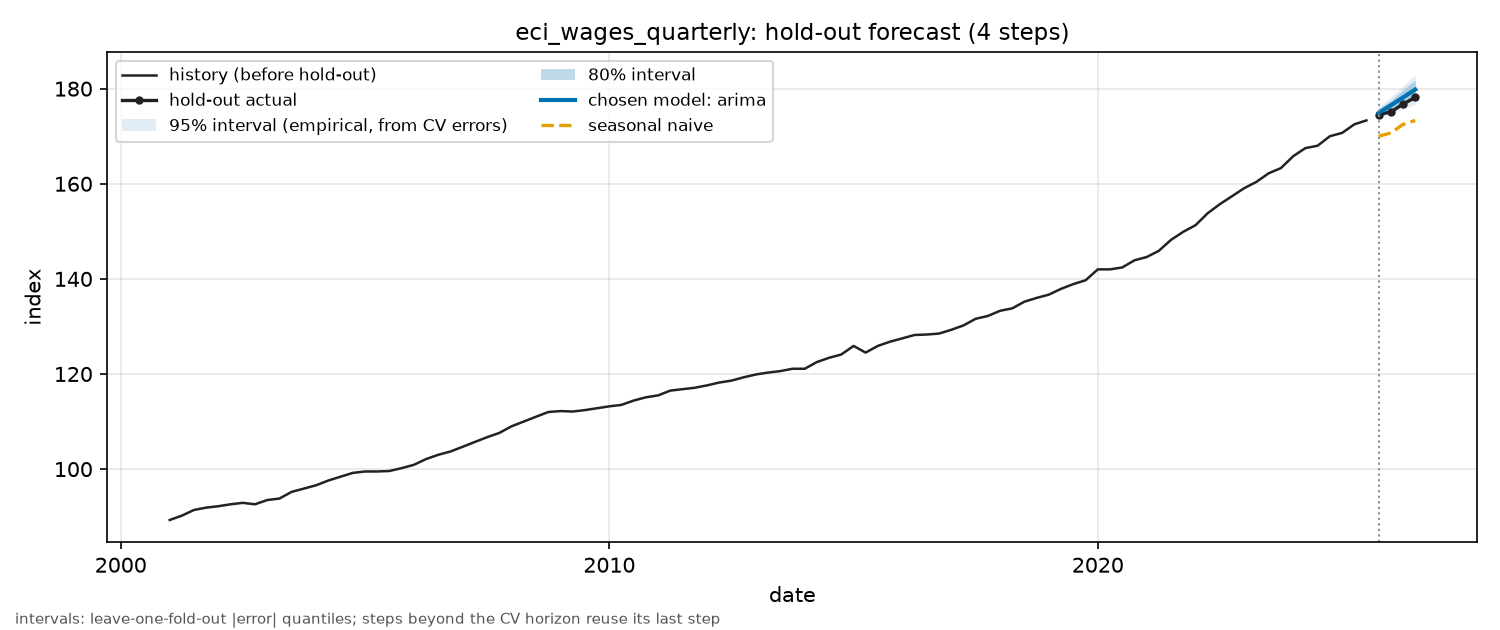

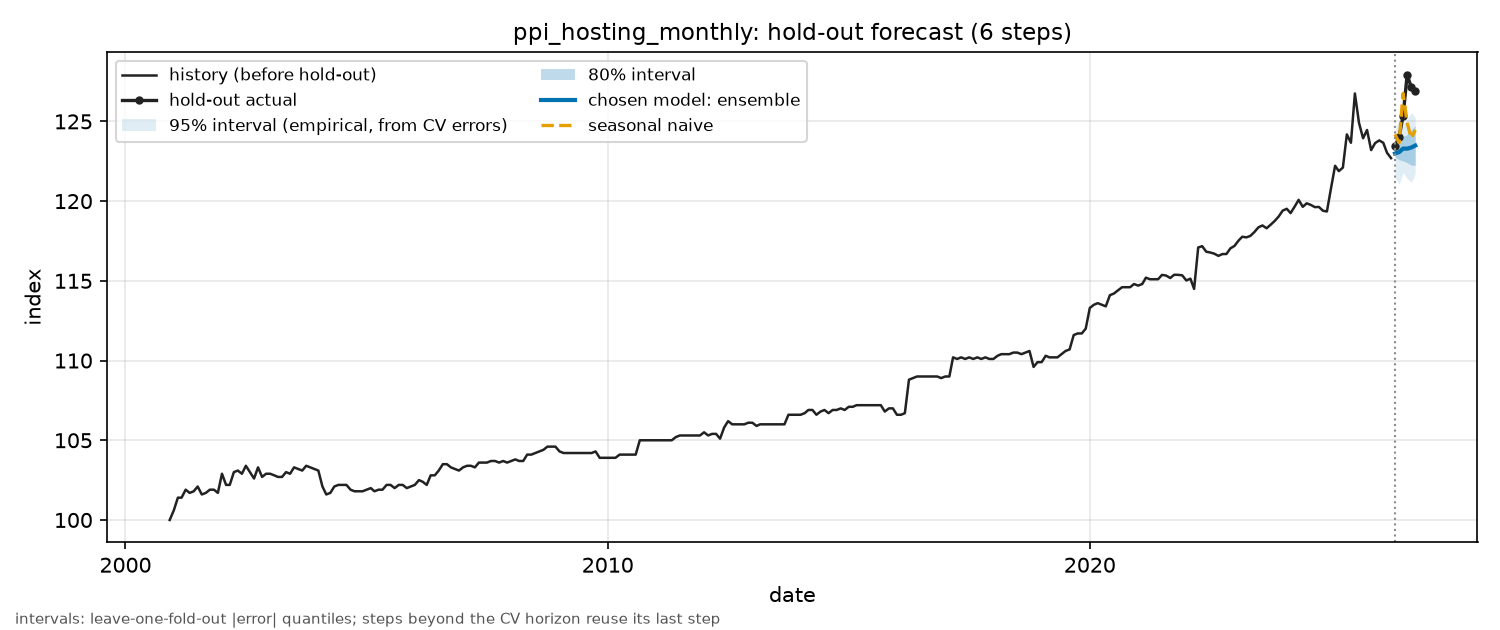

In [13]:
with step("forecasts"):
    for name in NAMES:
        show_img(f"outputs/phase2/figures/forecast_{name}.png", width=900)

## C7. Diagnostics: are the residuals just noise?
A good model leaves residuals (actual minus fitted) that look like **white noise**: no pattern left.
The **Ljung-Box test** checks this (p-value above 0.05 = looks like white noise). **Shapiro-Wilk** checks
normality. The **coverage** table checks the intervals: an 80% interval should contain about 80% of the
actual values; rows highlighted in orange fall short (below 60% for the 80% interval or below 85% for the 95% interval).

,driver,model,white_noise,ljung_box_p_lag10,ljung_box_p_lag14,ljung_box_p_lag48,ljung_box_p_lag8,ljung_box_p_lag24,shapiro_p,normal_residuals
0,burst_tokens_total_daily,ensemble,yes,0.781,0.923,NaN,NaN,NaN,0.000,no
1,burst_tokens_api_daily,ensemble,yes,0.787,0.929,NaN,NaN,NaN,0.000,no
2,burst_tokens_chat_daily,ensemble,no,0.014,0.009,NaN,NaN,NaN,0.567,yes
3,burst_requests_hourly,ensemble,no,0.000,NaN,0.0,NaN,NaN,0.000,no
4,wildchat_conversations_daily,seasonal_ma3,no,0.000,0.000,NaN,NaN,NaN,0.000,no
5,eci_wages_quarterly,arima,yes,0.316,NaN,NaN,0.24,NaN,0.020,no
6,ppi_hosting_monthly,ensemble,yes,0.088,NaN,NaN,NaN,0.72,0.000,no


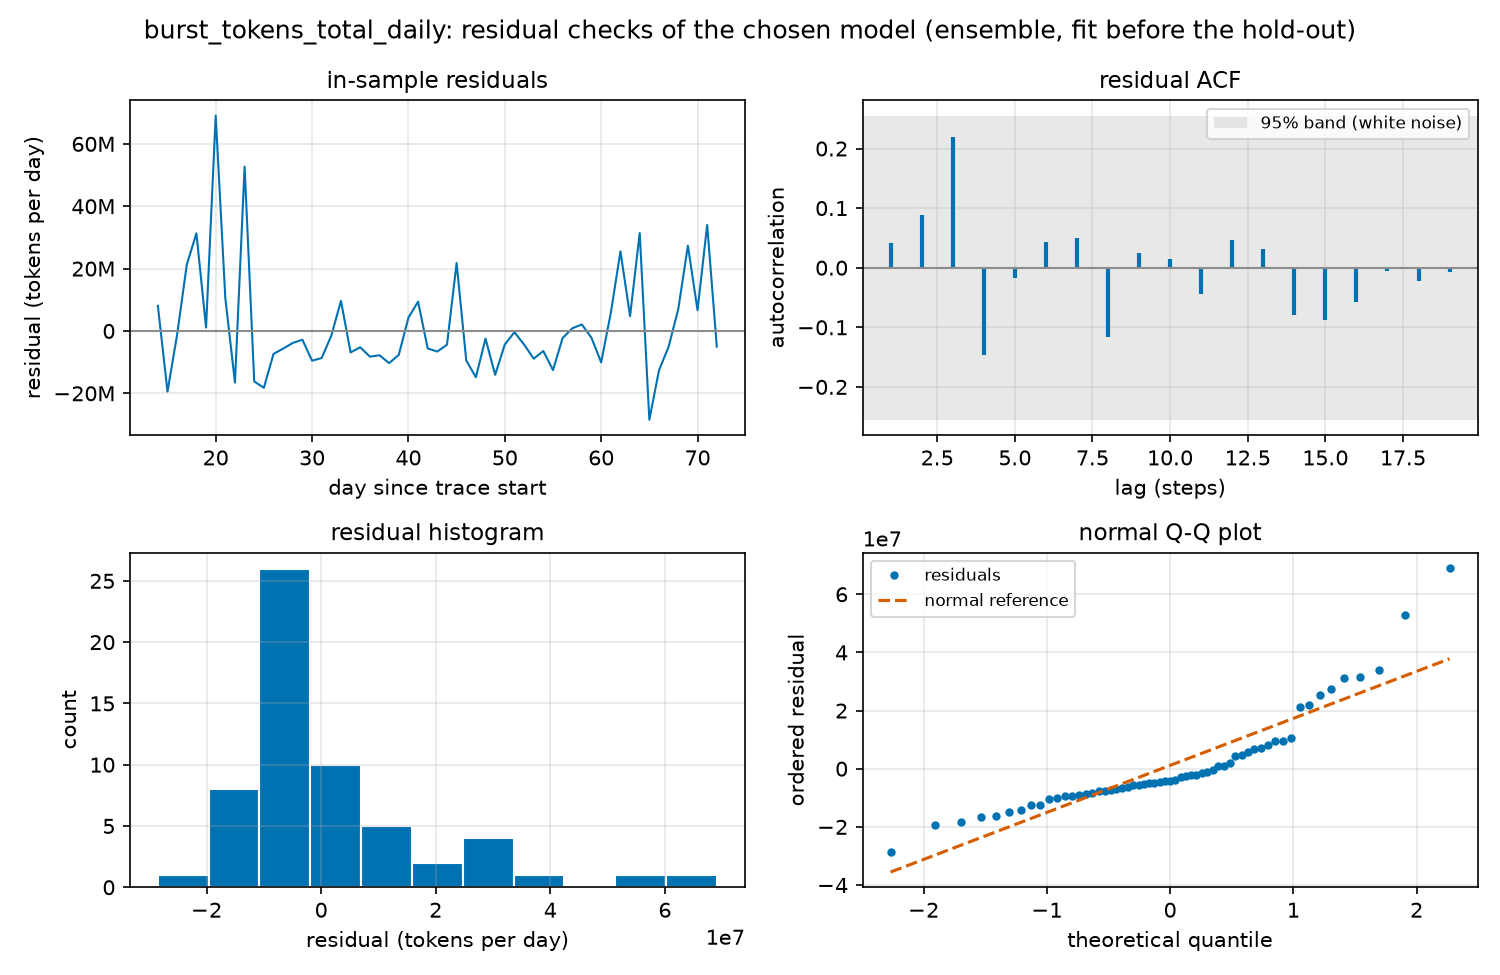

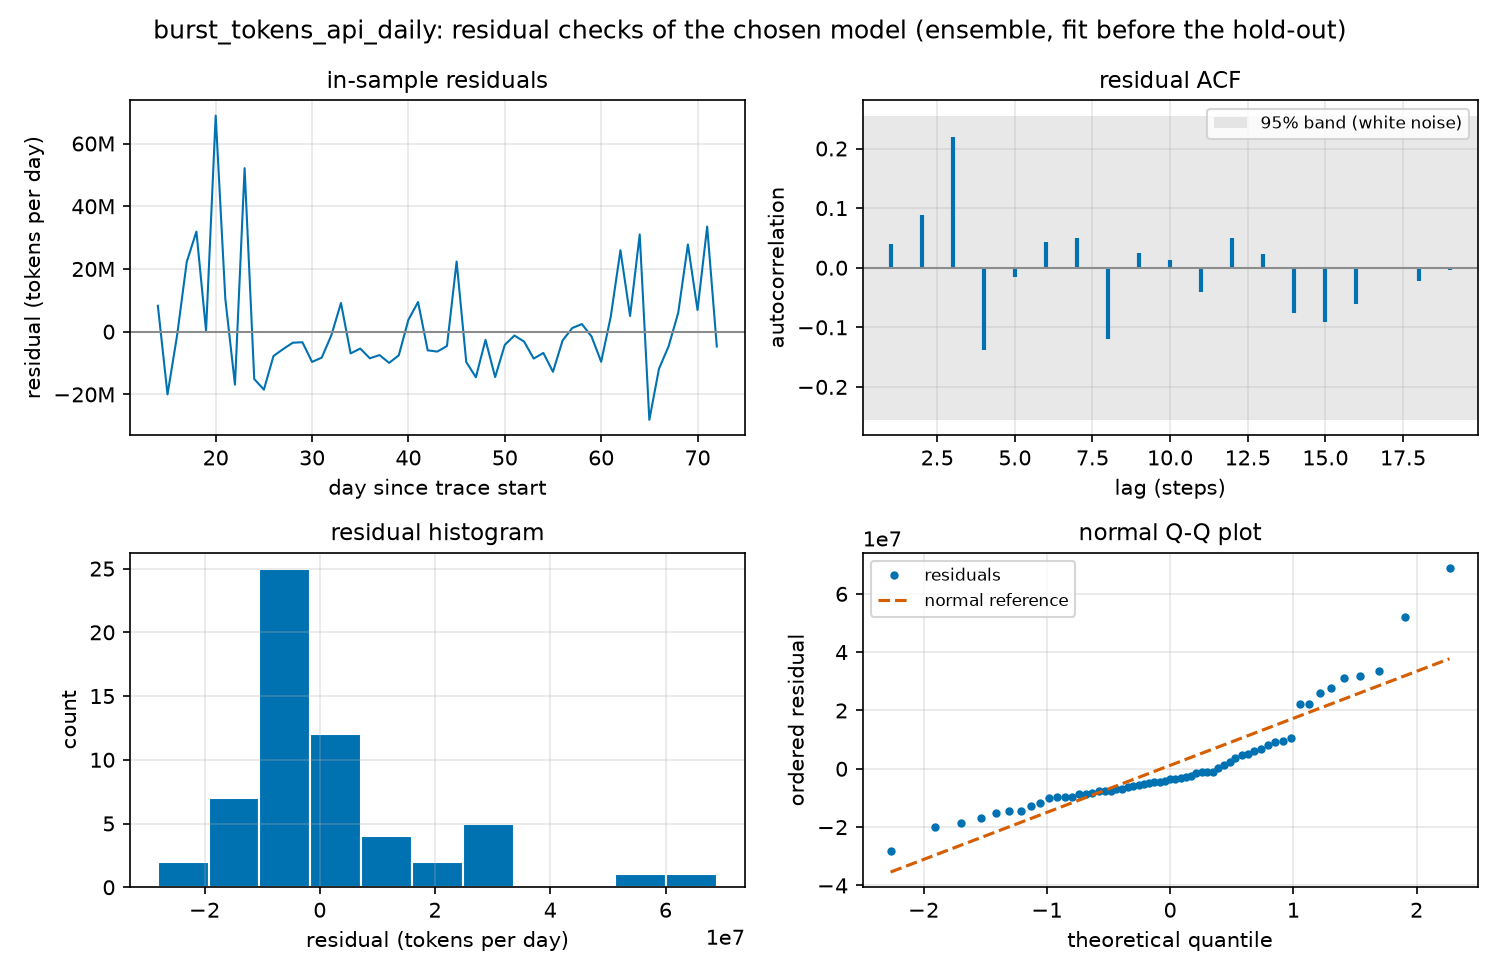

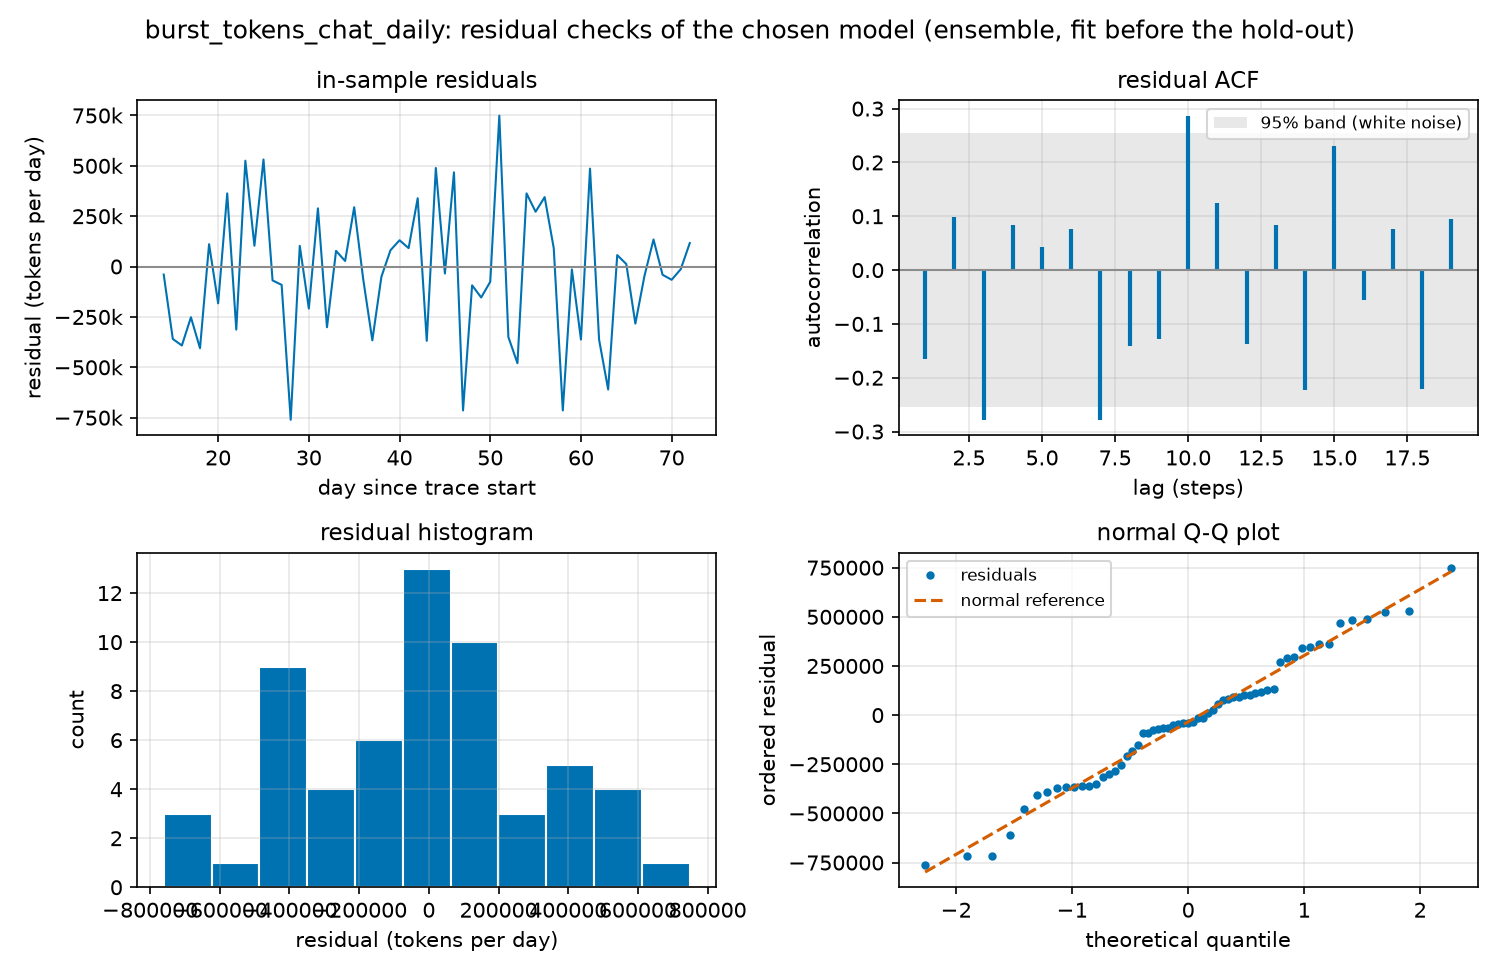

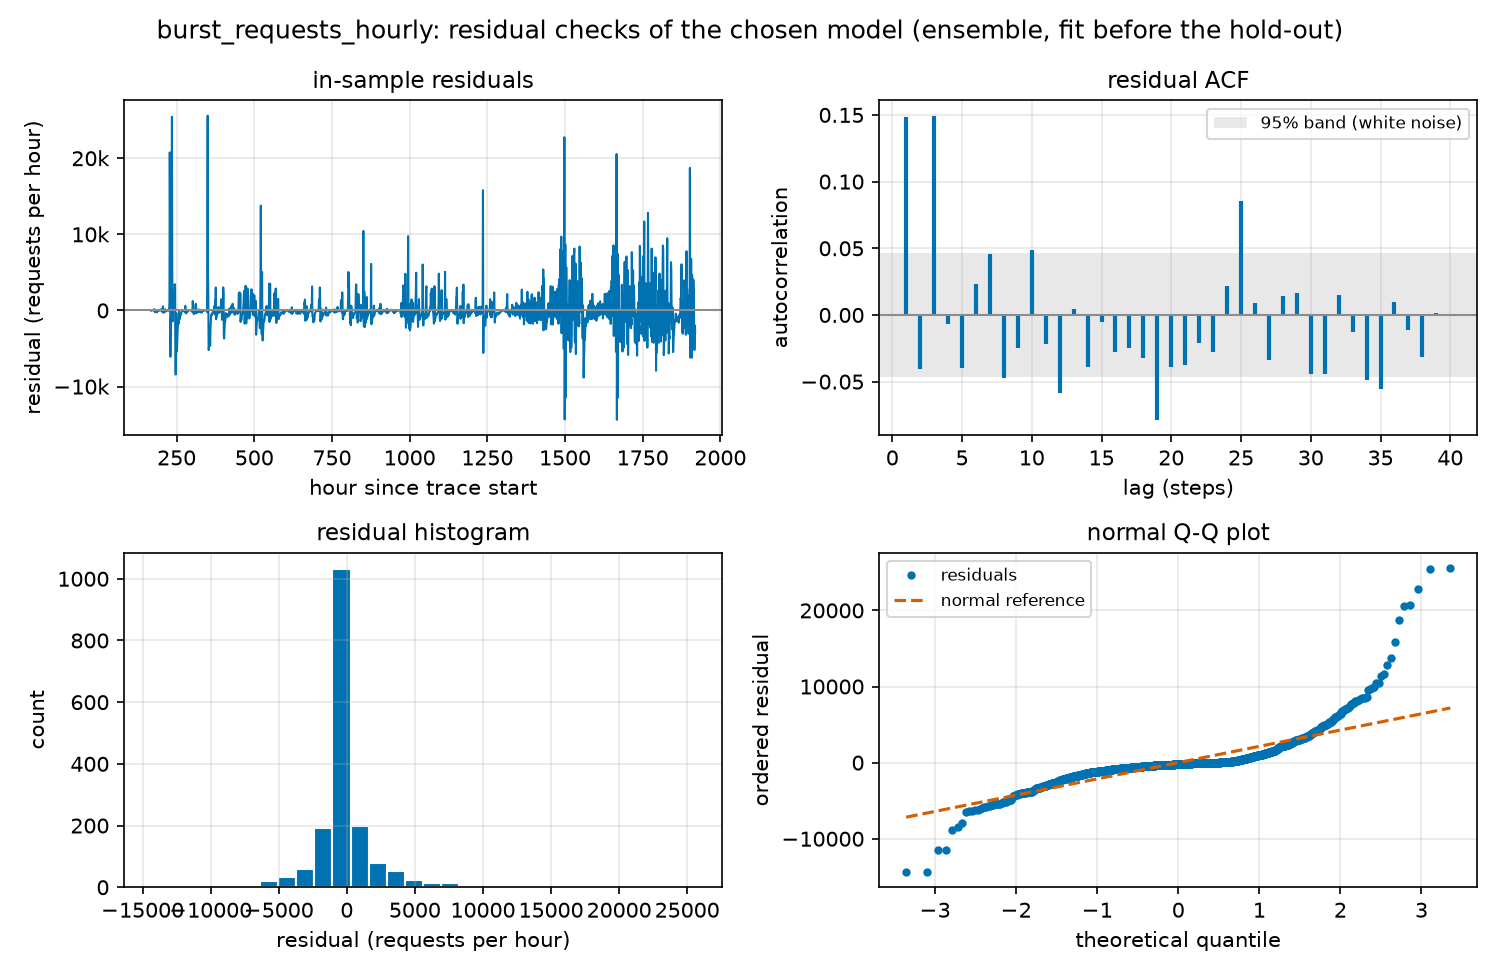

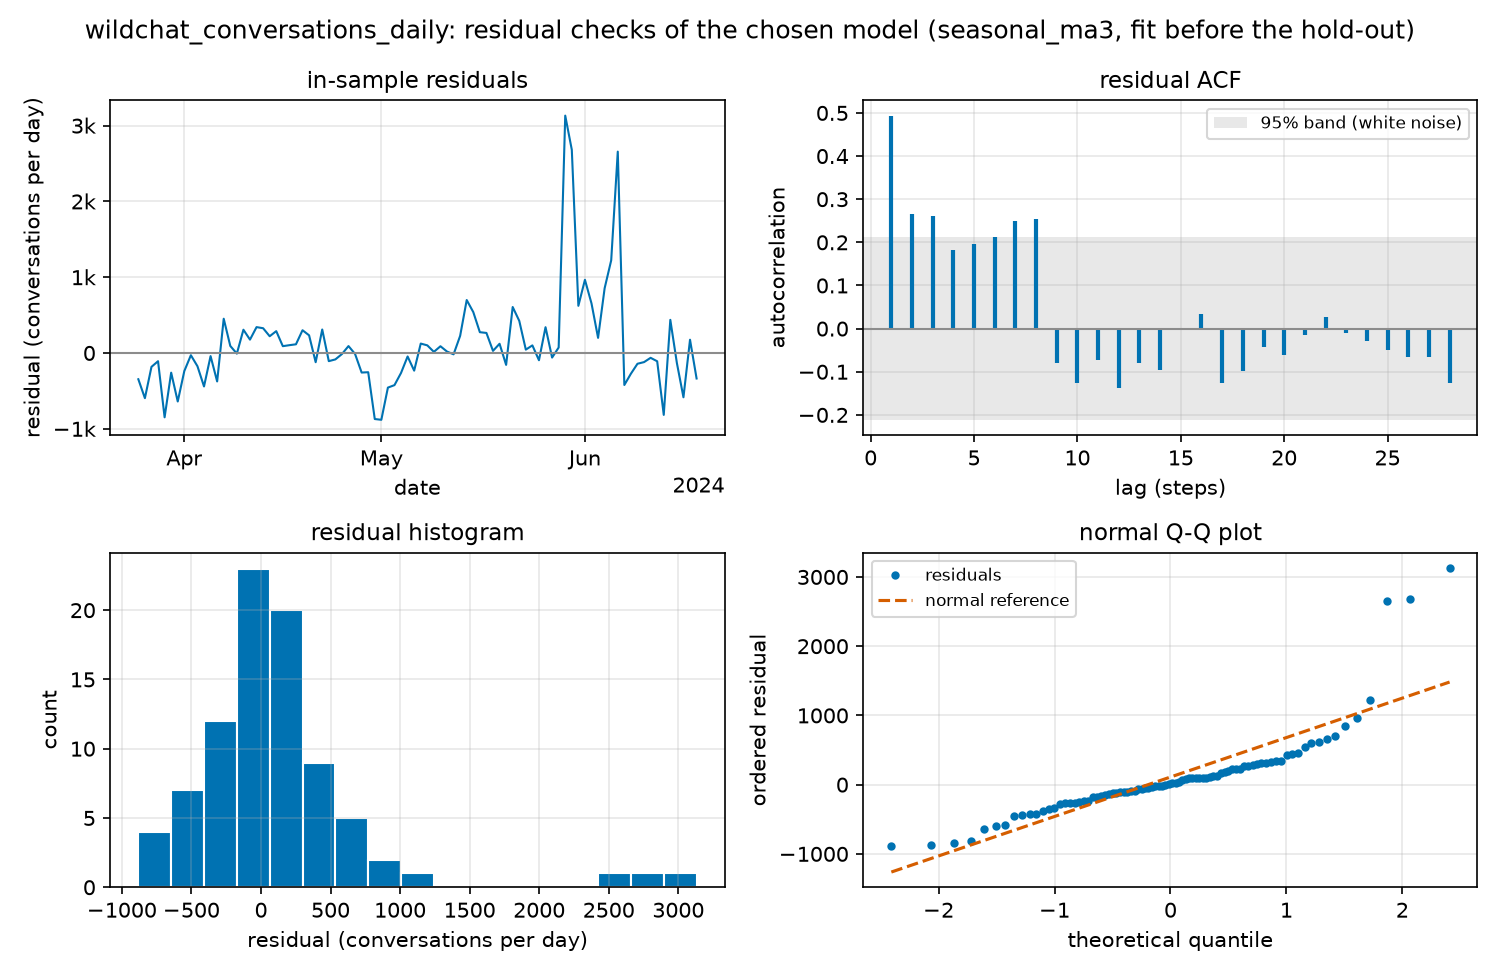

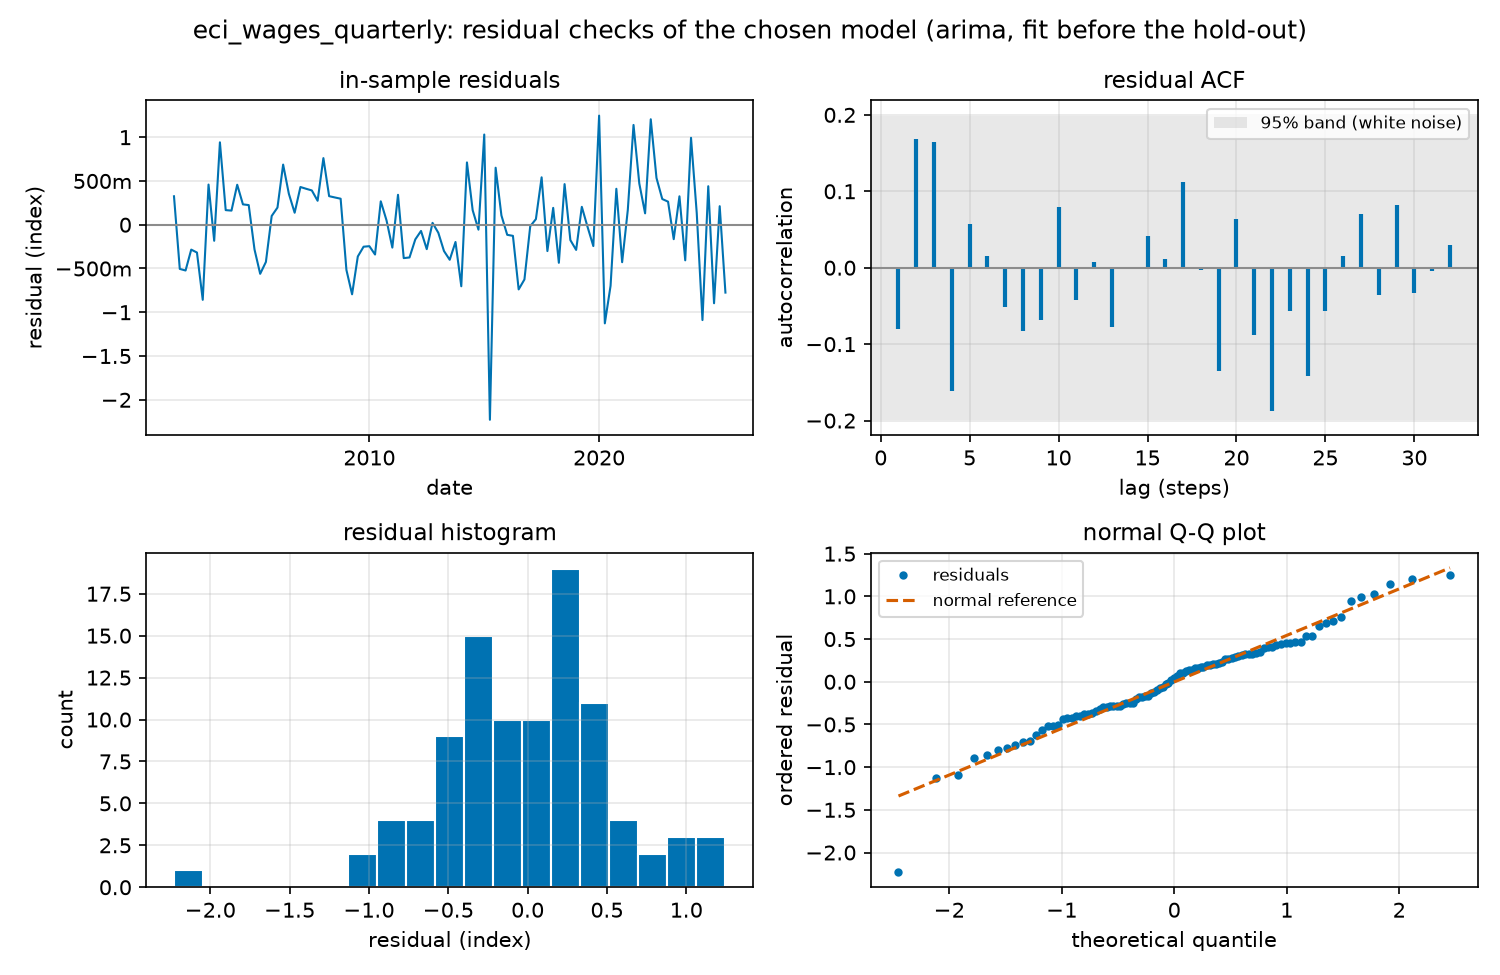

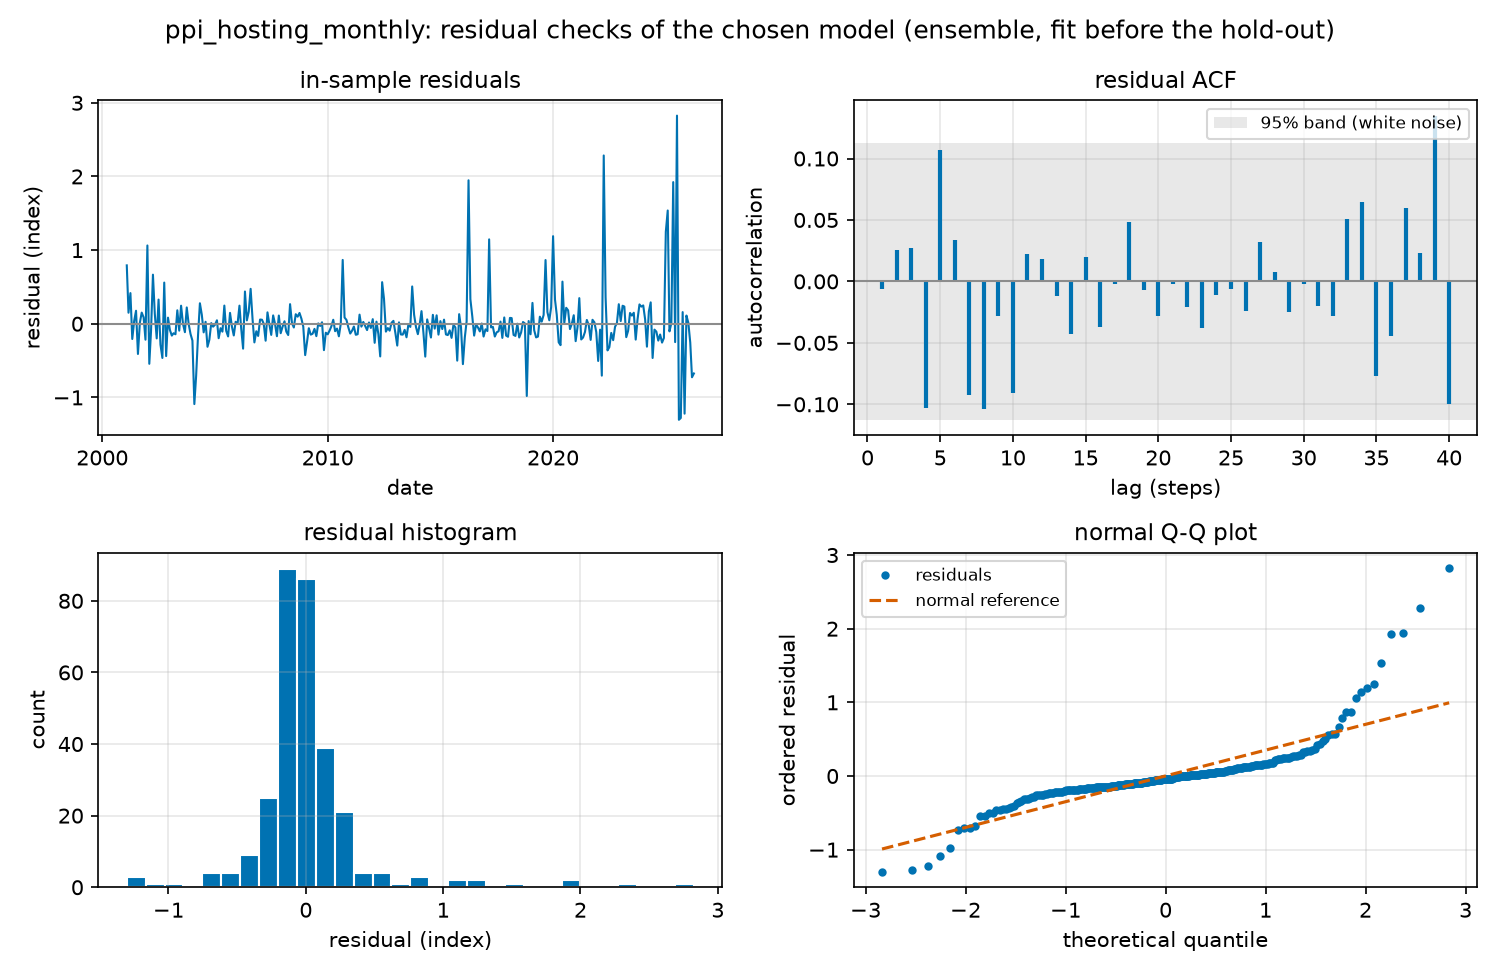

In [14]:
with step("residual diagnostics"):
    rd = read_table("phase2", "residual_diagnostics")
    lag_cols = [c for c in rd.columns if c.startswith("ljung_box_p_lag")]
    show_table(rd, n=20, cols=["driver", "model", "white_noise", *lag_cols, "shapiro_p", "normal_residuals"])
    for name in NAMES:
        show_img(f"outputs/phase2/figures/residuals_{name}.png", width=850)

In [15]:
with step("interval coverage"):
    cov = read_table("phase2", "interval_coverage")
    ch = read_table("phase2", "chosen_models")
    keep = set(zip(ch["driver"], ch["chosen_model"])) | {(d, "seasonal_naive") for d in ch["driver"]}
    sub = cov[[(d, m) in keep for d, m in zip(cov["driver"], cov["model"])]].copy()
    sub["flags"] = sub["flags"].fillna("")
    sub = sub[["driver", "model", "n_folds", "coverage_80", "coverage_95", "flags"]].round(3).reset_index(drop=True)
    print(f"{int(cov['flags'].fillna('').str.contains('coverage').sum())} of {len(cov)} model-series pairs have a coverage warning; "
          "chosen models and seasonal naive shown below.")
    try:
        display(sub.style.apply(lambda r: ["background-color: #FBD9C4" if "coverage" in r["flags"] else "" for _ in r], axis=1)
                .format(precision=3))
    except Exception:
        display(sub)

71 of 118 model-series pairs have a coverage warning; chosen models and seasonal naive shown below.


,driver,model,n_folds,coverage_80,coverage_95,flags
0,burst_tokens_total_daily,seasonal_naive,4,0.643,0.714,95% interval coverage 71.4% < 85%
1,burst_tokens_total_daily,ensemble,4,0.643,0.714,95% interval coverage 71.4% < 85%
2,burst_tokens_api_daily,seasonal_naive,4,0.643,0.750,95% interval coverage 75.0% < 85%
3,burst_tokens_api_daily,ensemble,4,0.643,0.679,95% interval coverage 67.9% < 85%
4,burst_tokens_chat_daily,seasonal_naive,4,0.750,0.750,95% interval coverage 75.0% < 85%
5,burst_tokens_chat_daily,ensemble,4,0.750,0.750,95% interval coverage 75.0% < 85%
6,burst_requests_hourly,seasonal_naive,8,0.729,0.859,
7,burst_requests_hourly,ensemble,8,0.719,0.849,95% interval coverage 84.9% < 85%
8,wildchat_conversations_daily,seasonal_naive,9,0.714,0.825,95% interval coverage 82.5% < 85%
9,wildchat_conversations_daily,seasonal_ma3,9,0.762,0.841,95% interval coverage 84.1% < 85%


## C8. Machine-learning insight
Tree models report **feature importance**: how much each input reduced the error. `lag_k` is the value
k steps earlier, `roll_mean` and `roll_std` summarise the last week (or day), `cycle_sin/cos` encode the
weekday or hour. For total tokens we also tried adding **requests** (lagged 14 days) as an extra input.

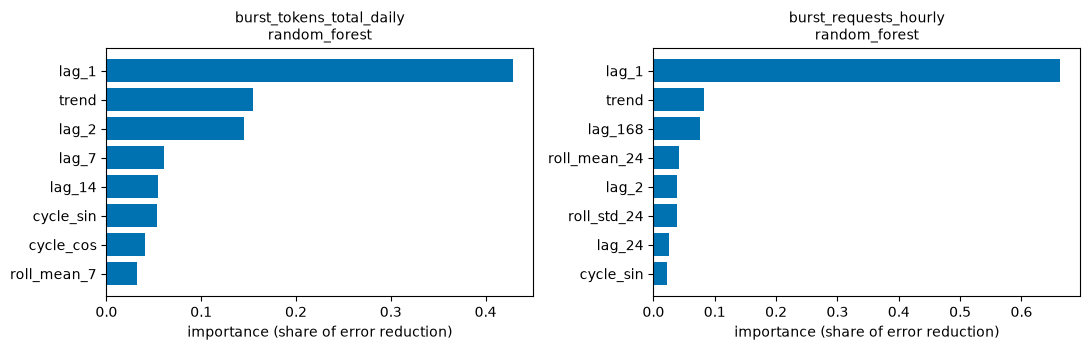

Mean CV MASE of the ML models on burst_tokens_total_daily, with and without requests:


variant,with requests,without,requests helped
base,,,
random_forest,0.842,0.809,False
ridge,0.505,0.496,False
xgboost,0.876,0.622,False


In [16]:
with step("feature importance"):
    import matplotlib.pyplot as plt
    fi = read_table("phase2", "feature_importance")
    pairs = [(d, "random_forest") for d in ("burst_tokens_total_daily", "burst_requests_hourly")
             if ((fi["driver"] == d) & (fi["model"] == "random_forest")).any()]
    if pairs:
        fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 3.6), squeeze=False)
        for ax, (d, m) in zip(axes[0], pairs):
            g = fi[(fi["driver"] == d) & (fi["model"] == m)].nlargest(8, "importance").iloc[::-1]
            ax.barh(g["feature"], g["importance"], color="#0072B2")
            ax.set_title(f"{d}\n{m}", fontsize=10)
            ax.set_xlabel("importance (share of error reduction)")
        plt.tight_layout()
        plt.show()
    lb = read_table("phase2", "leaderboard")
    t = lb[(lb["driver"] == "burst_tokens_total_daily") & (lb["family"] == "ml") & (lb["status"] == "ok")]
    if len(t):
        t = t.assign(base=t["model"].str.replace("_with_requests", "", regex=False),
                     variant=["with requests" if m.endswith("_with_requests") else "without" for m in t["model"]])
        comp = t.pivot(index="base", columns="variant", values="cv_mase").round(3)
        if {"with requests", "without"} <= set(comp.columns):
            comp["requests helped"] = comp["with requests"] < comp["without"]
        print("Mean CV MASE of the ML models on burst_tokens_total_daily, with and without requests:")
        display(comp)

**The recursive forecast** used by the machine-learning models: predict one step, append the prediction
to the history, rebuild the lag features, and repeat. This is how a one-step model produces a multi-step forecast.

In [17]:
with step("code: recursive forecast"):
    show_source("tsaf.models.ml", "recursive_forecast")

`tsaf.models.ml.recursive_forecast`
```python
def recursive_forecast(model, train: pd.Series, h: int, spec: FeatureSpec, grain: str,
                       extra: pd.Series | None = None) -> np.ndarray:
    """Predict one step, append it to the history, rebuild the features; repeat h times."""
    hist = pd.Series(np.asarray(train, dtype=float), index=train.index)
    labels = future_index(train.index, h, grain)
    preds = np.empty(h)
    for k in range(h):
        ext = pd.concat([hist, pd.Series([np.nan], index=labels[k:k + 1])])
        tail = ext.iloc[-spec.tail:]
        row = build_features(tail, spec, offset=len(ext) - len(tail), extra=extra).iloc[[-1]]
        if row.isna().any(axis=None):
            raise ValueError(f"step {k + 1}: feature row has NaN ({list(row.columns[row.isna().iloc[0]])})")
        preds[k] = float(np.asarray(model.predict(row)).reshape(-1)[0])
        ext.iloc[-1] = preds[k]
        hist = ext
    return preds
```

## C9. Prophet and LSTM (optional challengers)
Both are optional. Prophet needs the `prophet` package; the LSTM needs `torch` and the `--with-lstm` switch.

In [18]:
with step("prophet lstm"):
    lb = read_table("phase2", "leaderboard")
    for m in ("prophet", "lstm"):
        g = lb[lb["model"] == m]
        ran = g[g["status"] == "ok"]
        if len(ran):
            show_table(ran, cols=["driver", "model", "cv_mase", "holdout_mase"])
        else:
            reasons = sorted(set(g["reason"].fillna("")) - {""})
            why = next((r for r in reasons if "only for" not in r), reasons[0] if reasons else "not run")
            print(f"{m}: skipped (not installed or switched off): {why}")

prophet: skipped (not installed or switched off): skipped (not installed)
lstm: skipped (not installed or switched off): off by default (enable with --with-lstm)


## C10. Explore a series (optional, interactive)
Pick a series in the dropdown to see its leaderboard, forecast and residual figures together.
Nothing else in the notebook depends on this cell.

In [19]:
with step("explorer"):
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None
        print("ipywidgets is not available; the figures above show the same content.")
    if widgets is not None and NAMES:
        box = widgets.Output()
        dd = widgets.Dropdown(options=NAMES, value=NAMES[0], description="series")
        def _show(change=None):
            box.clear_output()
            with box:
                for kind, w in (("leaderboard", 600), ("forecast", 850), ("residuals", 800)):
                    show_img(f"outputs/phase2/figures/{kind}_{dd.value}.png", width=w)
        dd.observe(_show, names="value")
        display(dd, box)
        _show()

Dropdown(description='series', options=('burst_tokens_total_daily', 'burst_tokens_api_daily', 'burst_tokens_ch…

Output()

# Summary

The talking points and limitations below are taken directly from `PHASE2_SUMMARY.md`,
so every number comes from the run.

In [20]:
with step("summary"):
    for title in ("What to say in the review", "Limitations"):
        text = md_section("outputs/phase2/PHASE2_SUMMARY.md", title)
        display(Markdown(f"### Phase 2: {title}\n\n" + (text or "_Section not found._")))

### Phase 2: What to say in the review

Phase 2 scored 21 different models on 7 drivers, every model on the same expanding-window folds and hold-out as the Phase 1 baselines. A model beat seasonal naive on mean CV MASE for 7 of 7 drivers. The largest gain is on eci_wages_quarterly: arima reaches CV MASE 0.328 against 1.737 for seasonal naive (81% lower). For burst_tokens_total_daily the chosen model is ensemble (ensemble), CV MASE 0.424 and hold-out MASE 1.003. For burst_requests_hourly the chosen model is ensemble (ensemble), CV MASE 0.755 and hold-out MASE 1.834. Hold-out MASE is higher than CV MASE for 7 of 7 chosen models, so the final two weeks (or last periods) are harder than the backtest windows; the hold-out was never used for choosing. The chosen models come from these families: arima, baseline, ensemble; no single family wins everywhere. Empirical leave-one-fold-out intervals are too narrow for 71 of 118 model-driver pairs; with as few as 4 folds each interval rests on 3 errors per step. The day-77 outage check is FAIL (|robust z| 1.752 against 3.5). Hyper-parameters were chosen on the first training window only and kept fixed, so no fold ever saw its own test data.

### Phase 2: Limitations

- Short window: BurstGPT has 87 clean days (12 weeks); burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily have fewer than 5 folds, so mean CV MASE rests on few windows.
- Hyper-parameters (ARIMA orders, moving-average window, Ridge alpha) are tuned on the first training window only; smoothing parameters are re-estimated in every fold.
- Intervals are empirical (leave-one-fold-out quantiles of absolute errors); with few folds the 95% quantile is close to the largest of a handful of errors and under-covers.
- The ensemble's two components are picked by the same CV MASE it is then scored on, so its CV score is optimistic; its hold-out score is the fair check.
- BurstGPT weekend (day_of_cycle 4 and 5) is inferred from lower volume, not known.
- Prophet would use an arbitrary start date (2000-01-03) as an index only.
- burst_requests_hourly: the 8 capped folds (Phase 1 settings) test positions 336-863 of the 1920 pre-hold-out hours, not the most recent weeks.
- All models forecast the raw scale (no log transform), and forecasts are clipped at 0.

In [21]:
with step("what we have"):
    display(Markdown("### What we have so far"))
    display(pd.DataFrame([{"phase": "1. exploration and baselines", "built": "loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines, backtest", "outputs": "outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md", "notebook": "TSAF_Phase1.ipynb"}, {"phase": "2. forecasting models and rolling backtests", "built": "smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, model choice", "outputs": "outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMMARY.md", "notebook": "TSAF_Phase2.ipynb"}]))

### What we have so far

,phase,built,outputs,notebook
0,1. exploration and baselines,"loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines...","outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md",TSAF_Phase1.ipynb
1,2. forecasting models and rolling backtests,"smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, m...","outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMM...",TSAF_Phase2.ipynb


**Next: Phase 3** (`TSAF_Phase3.ipynb`) refits each chosen model and turns it into 200 simulated future paths in one standard table; it reads `chosen_models.json` and `cv_residuals.parquet` from the bundle.